# SC452 – Processes on Networks
## Assignment 8: Epidemic Spreading and Oscillator Synchronization (Numerical Section)

**Contents**
1. SIS dynamics on pairwise contact networks
2. SIR dynamics on pairwise contact networks
3. Synchronization of two coupled oscillators
4. Collective synchronization with all-to-all coupling

**General numerical approach (applies to all questions)**

* Every model here is an autonomous ODE system $\dot y = F(y)$. I wrote **one fixed-step classical 4th-order Runge–Kutta (RK4) routine** (`rk4_march`). It works on whole *batches* of independent systems held in one NumPy array, e.g. all 51 values of $\lambda$ at once. Sweeps therefore cost about as much as a single run.
* Why a fixed step: the time grids required by the questions (time averages over windows, $t_{peak}$, settling times, phase-slip crossings) come out on a uniform grid, and the right-hand sides are smooth and non-stiff. The fastest local rate is $\lesssim \mu+\lambda\Lambda_{max}\approx 6$ for the epidemics and $|\omega_i|+K \lesssim 7$ for the oscillators. With $\Delta t \le 0.05$ we have $\Delta t \cdot \text{rate} \le 0.35$, well inside the RK4 stability region ($\approx 2.8$).
* **Accuracy checks:** each question repeats representative runs with (i) half or a fifth of the step size and (ii) SciPy's adaptive `DOP853` solver at very tight tolerances (`rtol=1e-10, atol=1e-12`), and reports the maximum deviation.
* **Networks are generated from scratch** (no NetworkX/igraph). Eigenvalues come from `numpy.linalg.eigvalsh` (the adjacency matrices are symmetric).
* Stopping criteria are stated in each part where they are needed (persistence test in 1b, $\max_i I_i<10^{-8}$ in 2, settling/locking tests in 3–4).

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "font.size": 10, "legend.fontsize": 8})
np.set_printoptions(precision=5, suppress=True)
CLOCK = time.time()


def rk4_march(field, y0, t_end, dt, probe=None, every=1, t0=0.0):
    """Fixed-step RK4 for an autonomous field F(y) acting on an ndarray of any shape.

    probe(y) -> ndarray is evaluated at t0 and after every `every` steps;
    its outputs are stacked along a new first axis.
    Returns (final state, sample times, stacked probe outputs)."""
    n_steps = int(round((t_end - t0) / dt))
    y = np.array(y0, dtype=float)
    stamps, records = [], []
    if probe is not None:
        stamps.append(t0); records.append(probe(y))
    h2, h6 = 0.5 * dt, dt / 6.0
    for step in range(1, n_steps + 1):
        a = field(y)
        b = field(y + h2 * a)
        c = field(y + h2 * b)
        d = field(y + dt * c)
        y = y + h6 * (a + 2.0 * b + 2.0 * c + d)
        if probe is not None and step % every == 0:
            stamps.append(t0 + step * dt); records.append(probe(y))
    if probe is None:
        return y, None, None
    return y, np.array(stamps), np.array(records)


def window_mean(t, f, a, b):
    """(1/(b-a)) * integral_a^b f dt via the trapezoid rule; f may carry extra trailing axes."""
    sel = (t >= a - 1e-9) & (t <= b + 1e-9)
    return np.trapezoid(f[sel], t[sel], axis=0) / (b - a)


def degree_rank(deg, highest=True):
    """Node indices ordered by degree (descending if highest), ties broken by smaller index."""
    idx = np.arange(len(deg))
    key = -deg if highest else deg
    return np.lexsort((idx, key))

---
# Question 1 — SIS dynamics

$$\dot x_i = -\mu x_i + \lambda (1-x_i)\sum_j A_{ij}x_j ,\qquad \mu = 1,\; x_i(0)=0.01 .$$

### Building the networks (own implementation)
* **Erdős–Rényi $G(N,p)$:** every one of the $\binom{N}{2}$ node pairs is kept independently with probability $p=0.04$. A single `default_rng(42)` draws the upper triangle, which is then mirrored.
* **Barabási–Albert:** start from a complete core of $m+1=7$ nodes. Each new node attaches to $m=6$ *distinct* existing nodes, chosen with probability proportional to degree. This is done by sampling uniformly from a list holding every edge endpoint. Seed 42 (its own generator).

All 300 nodes are kept. Connectivity is checked with a breadth-first search.

In [2]:
def erdos_renyi(n, p, seed):
    gen = np.random.default_rng(seed)
    keep = np.triu(gen.random((n, n)) < p, k=1)
    return (keep | keep.T).astype(float)


def barabasi_albert(n, m, seed):
    gen = np.random.default_rng(seed)
    adj = np.zeros((n, n))
    core = m + 1
    adj[:core, :core] = 1.0 - np.eye(core)
    endpoints = [u for u in range(core) for _ in range(core - 1)]  # node u repeated deg(u) times
    for newcomer in range(core, n):
        chosen = set()
        while len(chosen) < m:
            chosen.add(endpoints[gen.integers(len(endpoints))])
        for v in chosen:
            adj[newcomer, v] = adj[v, newcomer] = 1.0
            endpoints.extend((newcomer, v))
    return adj


def component_count(adj):
    n = len(adj); seen = np.zeros(n, bool); groups = 0
    nbrs = [np.flatnonzero(row) for row in adj]
    for s in range(n):
        if seen[s]:
            continue
        groups += 1; queue = [s]; seen[s] = True
        while queue:
            u = queue.pop()
            for w in nbrs[u]:
                if not seen[w]:
                    seen[w] = True; queue.append(w)
    return groups


def top_eigenvalue(adj):
    return np.linalg.eigvalsh(adj)[-1]


NODES = 300
MU = 1.0
graphs = {"ER": erdos_renyi(NODES, 0.04, 42), "BA": barabasi_albert(NODES, 6, 42)}
degrees = {g: A.sum(1) for g, A in graphs.items()}
lam_ref = {}
print(f"{'net':4s}{'edges':>7s}{'<k>':>8s}{'k_min':>7s}{'k_max':>7s}{'<k^2>/<k>':>11s}{'comps':>7s}{'Lmax':>9s}{'lam_ref':>9s}")
for g, A in graphs.items():
    k = degrees[g]; L = top_eigenvalue(A); lam_ref[g] = MU / L
    print(f"{g:4s}{int(A.sum()/2):7d}{k.mean():8.3f}{int(k.min()):7d}{int(k.max()):7d}"
          f"{(k**2).mean()/k.mean():11.3f}{component_count(A):7d}{L:9.4f}{lam_ref[g]:9.5f}")
assert all(np.allclose(A, A.T) and np.all(np.diag(A) == 0) for A in graphs.values())

net   edges     <k>  k_min  k_max  <k^2>/<k>  comps     Lmax  lam_ref
ER     1787  11.913      4     24     12.932      1  13.0257  0.07677
BA     1779  11.860      6     73     20.397      1  19.9768  0.05006


In [3]:
def sis_field(A, lam, mu=MU):
    """Batched SIS right-hand side. X has shape (..., B, N); lam has shape (B,).
    A may be one (N,N) matrix or a stack (S,N,N) matched to X of shape (S,B,N)."""
    rate = np.asarray(lam, float)[:, None]
    return lambda X: -mu * X + rate * (1.0 - X) * (X @ A)


def sis_rhs_scipy(A, lam, mu=MU):
    return lambda t, x: -mu * x + lam * (1.0 - x) * (A @ x)

## 1(a) Time evolution of $\rho(t)$ for $\lambda = 0.02, 0.06, 0.10, 0.20$
RK4 with $\Delta t = 0.05$ over $0\le t\le300$; all four $\lambda$ are integrated together as a batch.

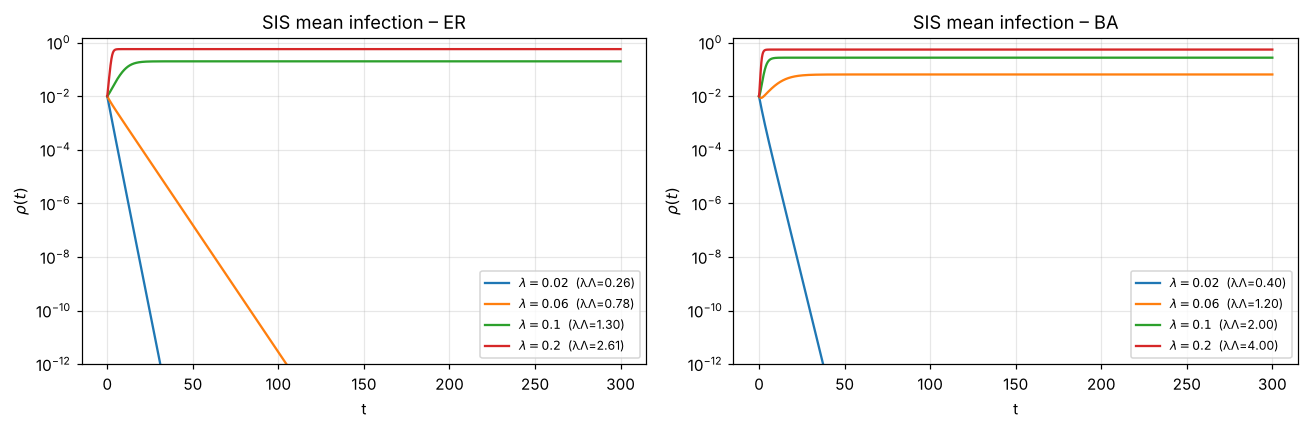

rho(300):
  ER: λ=0.02: 4.0399e-99, λ=0.06: 2.9901e-31, λ=0.1: 2.0078e-01, λ=0.2: 5.7349e-01
  BA: λ=0.02: 3.4092e-81, λ=0.06: 6.4917e-02, λ=0.1: 2.7483e-01, λ=0.2: 5.5206e-01


In [4]:
lam_a = np.array([0.02, 0.06, 0.10, 0.20])
DT_SIS = 0.05
rho_traces = {}
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (g, A) in zip(axes, graphs.items()):
    X0 = np.full((len(lam_a), NODES), 0.01)
    _, ts, rho = rk4_march(sis_field(A, lam_a), X0, 300, DT_SIS, probe=lambda X: X.mean(-1))
    rho_traces[g] = (ts, rho)
    for j, lam in enumerate(lam_a):
        ax.plot(ts, rho[:, j], label=fr"$\lambda={lam}$  (λΛ={lam/lam_ref[g]:.2f})")
    ax.set_yscale("log"); ax.set_ylim(1e-12, 1.5)
    ax.set_xlabel("t"); ax.set_ylabel(r"$\rho(t)$"); ax.set_title(f"SIS mean infection – {g}")
    ax.legend()
plt.tight_layout(); plt.show()

print("rho(300):")
for g in graphs:
    print(f"  {g}: " + ", ".join(f"λ={l}: {v:.4e}" for l, v in zip(lam_a, rho_traces[g][1][-1])))

**Observations 1(a).** The relevant number is $\lambda\Lambda_{max}$, with $\Lambda_{max}=13.03$ (ER) and $19.98$ (BA).
* ER: for $\lambda=0.02$ and $0.06$ ($\lambda\Lambda=0.26,\,0.78<1$) $\rho(t)$ decays exponentially to zero. The measured decay rate for $\lambda=0.02$ is $\ln(\rho(300)/\rho(0))/300\approx-0.74$, which matches the linear prediction $-(1-\lambda\Lambda_{max})=-0.74$. For $\lambda=0.10$ and $0.20$ ($\lambda\Lambda>1$) the infection settles to endemic levels $\rho\approx0.20$ and $0.57$.
* BA: $\lambda=0.06$ already gives $\lambda\Lambda_{max}=1.20>1$, so the infection persists ($\rho\approx0.065$) on the BA network but dies out on the ER network at the same $\lambda$. The hubs of the heterogeneous network raise $\Lambda_{max}$ and therefore lower the threshold.
* Endemic states are reached within $t\approx20$–$40$, well before the averaging window $[250,300]$.

**Convergence check.** The same runs are repeated with $\Delta t=0.01$ and with adaptive DOP853 (`rtol=1e-10`, `atol=1e-12`), and compared on the common output grid.

In [5]:
print(f"{'net':4s}{'lambda':>8s}{'max|ρ(dt=.05)-ρ(dt=.01)|':>27s}{'max|ρ(dt=.05)-ρ(DOP853)|':>27s}{'rel.err ρ(300)':>16s}")
for g, A in graphs.items():
    ts, rho = rho_traces[g]
    X0 = np.full((len(lam_a), NODES), 0.01)
    _, ts_f, rho_f = rk4_march(sis_field(A, lam_a), X0, 300, 0.01, probe=lambda X: X.mean(-1), every=5)
    for j, lam in enumerate(lam_a):
        ref = solve_ivp(sis_rhs_scipy(A, lam), (0, 300), np.full(NODES, 0.01), method="DOP853",
                        rtol=1e-10, atol=1e-12, t_eval=ts)
        rho_ref = ref.y.mean(0)
        e1 = np.max(np.abs(rho[:, j] - rho_f[:, j])); e2 = np.max(np.abs(rho[:, j] - rho_ref))
        rel = abs(rho[-1, j] - rho_ref[-1]) / max(rho_ref[-1], 1e-300)
        print(f"{g:4s}{lam:8.2f}{e1:27.3e}{e2:27.3e}{rel:16.2e}")

net   lambda   max|ρ(dt=.05)-ρ(dt=.01)|   max|ρ(dt=.05)-ρ(DOP853)|  rel.err ρ(300)


ER      0.02                  7.064e-11                  7.116e-11        1.00e+00
ER      0.06                  1.612e-11                  1.627e-11       1.10e+285
ER      0.10                  2.162e-11                  7.342e-11        7.92e-13


ER      0.20                  9.002e-08                  9.018e-08        2.42e-13


BA      0.02                  9.756e-11                  9.820e-11       3.62e+286
BA      0.06                  1.108e-10                  3.054e-10        1.76e-12
BA      0.10                  3.571e-09                  3.578e-09        5.92e-13


BA      0.20                  6.579e-07                  6.591e-07        7.66e-13


**Accuracy 1(a).** Halving/fifthing the step and switching to DOP853 change $\rho(t)$ by at most $7\times10^{-7}$ (absolute). This is the "convergence" criterion: results agree well below plotting resolution. The *relative* error column is meaningful only for endemic runs, where it is $\sim10^{-12}$. For the dying runs $\rho(300)\sim10^{-31}$–$10^{-99}$, far below the reference solver's absolute tolerance ($10^{-12}$). Both solutions are numerically zero there, so their ratio is meaningless.

## 1(b) Long-time average $\bar\rho$ versus $\lambda$ and the epidemic threshold
Every $\lambda\in\{0,0.005,\dots,0.25\}$ restarts from $x_i(0)=0.01$. One batch run per network gives
$\bar\rho = \frac{1}{50}\int_{250}^{300}\rho\,dt$ (trapezoid rule on the $\Delta t=0.05$ grid).

**Persistence criterion.** Infection is called *persistent* if both of these hold at the end of the run:
1. Level test: $\bar\rho > 10^{-6}$ over the final window of length 50.
2. Trend test: the late-time logarithmic growth rate $s=\ln[\rho(T)/\rho(T-50)]/50$ satisfies $s > -10^{-3}$, i.e. $\rho$ has stopped decaying exponentially.

Below threshold the linearisation gives $\rho\propto e^{-(\mu-\lambda\Lambda_{max})t}$, which fails the trend test. Above threshold $\rho$ settles on a positive endemic value, which passes both tests.

ER: coarse onset (first persistent λ, T=300) = 0.080;  λ_ref = 1/Λmax = 0.07677


BA: coarse onset (first persistent λ, T=300) = 0.055;  λ_ref = 1/Λmax = 0.05006


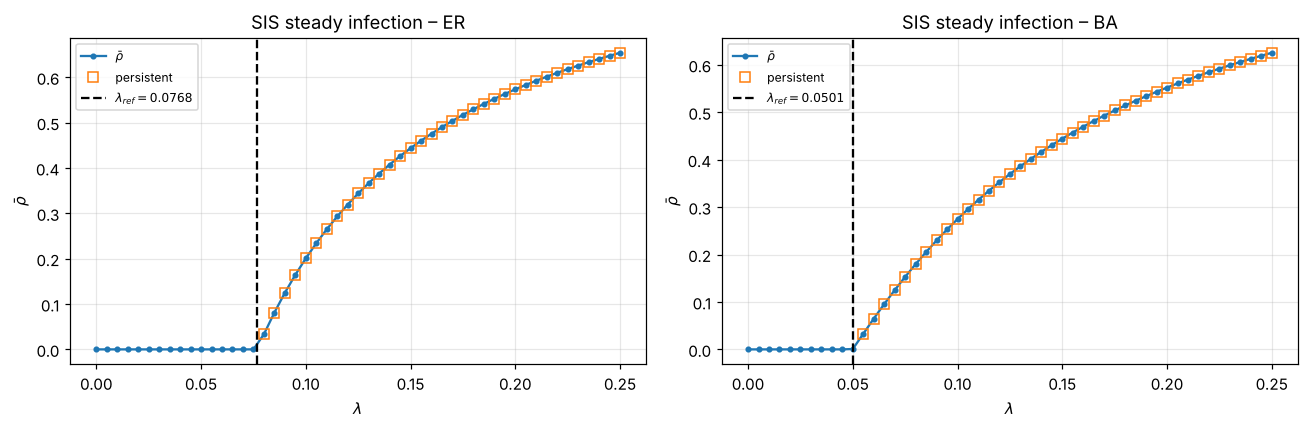

In [6]:
lam_grid = np.round(np.arange(0, 0.25 + 1e-12, 0.005), 3)


def sis_sweep(A, lams, x0, t_end, dt=DT_SIS, every=1):
    X0 = np.broadcast_to(x0, A.shape[:-2] + (len(lams), A.shape[-1])).copy()
    _, ts, rho = rk4_march(sis_field(A, lams), X0, t_end, dt, probe=lambda X: X.mean(-1), every=every)
    w = t_end - 50
    avg = window_mean(ts, rho, w, t_end)
    i_end, i_w = -1, np.argmin(np.abs(ts - w))
    with np.errstate(divide="ignore", invalid="ignore"):
        slope = np.log(rho[i_end] / rho[i_w]) / 50.0
    persistent = (avg > 1e-6) & (slope > -1e-3)
    return avg, slope, persistent


sweep_b = {}
for g, A in graphs.items():
    sweep_b[g] = sis_sweep(A, lam_grid, 0.01, 300)
    avg, slope, pers = sweep_b[g]
    onset = lam_grid[np.argmax(pers)] if pers.any() else np.nan
    print(f"{g}: coarse onset (first persistent λ, T=300) = {onset:.3f};  λ_ref = 1/Λmax = {lam_ref[g]:.5f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (g, (avg, slope, pers)) in zip(axes, sweep_b.items()):
    ax.plot(lam_grid, avg, "o-", ms=3, label=r"$\bar\rho$")
    ax.plot(lam_grid[pers], avg[pers], "s", mfc="none", ms=6, label="persistent")
    ax.axvline(lam_ref[g], color="k", ls="--", label=fr"$\lambda_{{ref}}={lam_ref[g]:.4f}$")
    ax.set_xlabel(r"$\lambda$"); ax.set_ylabel(r"$\bar\rho$"); ax.set_title(f"SIS steady infection – {g}")
    ax.legend()
plt.tight_layout(); plt.show()

**Refinement near $\lambda_{ref}$.** Grid spacing $0.0005$ over $\lambda_{ref}\pm0.01$, with the integration extended to $T=3000$ so that slow (critical) decay just below threshold has time to show up. The same two-part test is applied over $[2950,3000]$.

ER  T=  300: onset bracketed in (0.07677, 0.07727];  λ_ref=0.07677;  (first−λ_ref)/λ_ref = +0.651%


ER  T= 3000: onset bracketed in (0.07627, 0.07677];  λ_ref=0.07677;  (first−λ_ref)/λ_ref = -0.000%


BA  T=  300: onset bracketed in (0.05006, 0.05056];  λ_ref=0.05006;  (first−λ_ref)/λ_ref = +0.999%


BA  T= 3000: onset bracketed in (0.04956, 0.05006];  λ_ref=0.05006;  (first−λ_ref)/λ_ref = -0.000%


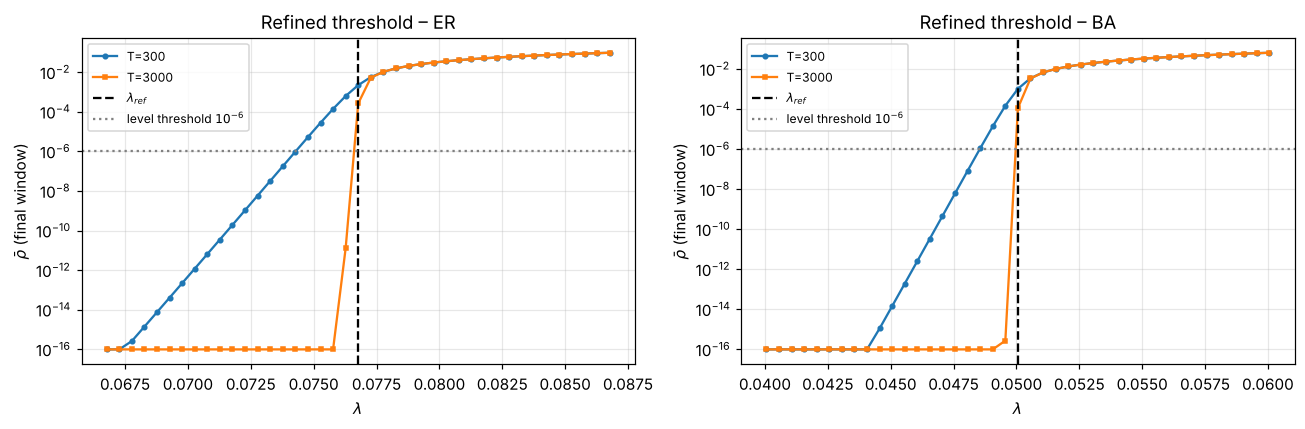

In [7]:
refined = {}
for g, A in graphs.items():
    lr = lam_ref[g]
    fine = np.round(np.arange(lr - 0.01, lr + 0.01 + 1e-12, 0.0005), 6)
    for T_end in (300, 3000):
        avg, slope, pers = sis_sweep(A, fine, 0.01, T_end, every=10)
        refined[(g, T_end)] = (fine, avg, slope, pers)
        first = fine[np.argmax(pers)] if pers.any() else np.nan
        last_dead = fine[~pers][fine[~pers] < first].max() if (~pers).any() else np.nan
        print(f"{g}  T={T_end:5d}: onset bracketed in ({last_dead:.5f}, {first:.5f}];"
              f"  λ_ref={lr:.5f};  (first−λ_ref)/λ_ref = {(first-lr)/lr:+.3%}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, g in zip(axes, graphs):
    for T_end, mk in ((300, "o"), (3000, "s")):
        fine, avg, slope, pers = refined[(g, T_end)]
        ax.semilogy(fine, np.maximum(avg, 1e-16), mk + "-", ms=3, label=f"T={T_end}")
    ax.axvline(lam_ref[g], color="k", ls="--", label=r"$\lambda_{ref}$")
    ax.axhline(1e-6, color="gray", ls=":", label="level threshold $10^{-6}$")
    ax.set_xlabel(r"$\lambda$"); ax.set_ylabel(r"$\bar\rho$ (final window)"); ax.set_title(f"Refined threshold – {g}")
    ax.legend()
plt.tight_layout(); plt.show()

**Observations 1(b).**
* On the coarse grid the first persistent $\lambda$ is $0.080$ (ER) and $0.055$ (BA). These are simply the first grid points above $\lambda_{ref}=0.0768$ and $0.0501$. (For BA, $0.050$ lies just *below* $\lambda_{ref}=0.05006$.)
* On the refined grid with $T=3000$ the onset coincides with $\lambda_{ref}$ to within the grid spacing $5\times10^{-4}$ for both networks. This agrees with the linear stability of $x=0$: the Jacobian there is $-\mu I+\lambda A$, which becomes unstable exactly when $\lambda\Lambda_{max}=\mu$.
* With $T=300$ the detected onset moves up by one grid step. Close to threshold the relaxation rate $|1-\lambda\Lambda_{max}|\to0$ (*critical slowing down*), so finite integration time biases the estimate. This is why the time was extended.
* The ER curve rises sharply above threshold. The BA curve starts lower but rises more gradually, because just above threshold the infection is concentrated on the hubs (the principal eigenvector is localised on high-degree nodes). The average over all nodes stays small at first.

## 1(c) Node-level infection versus degree at $\lambda=0.10$

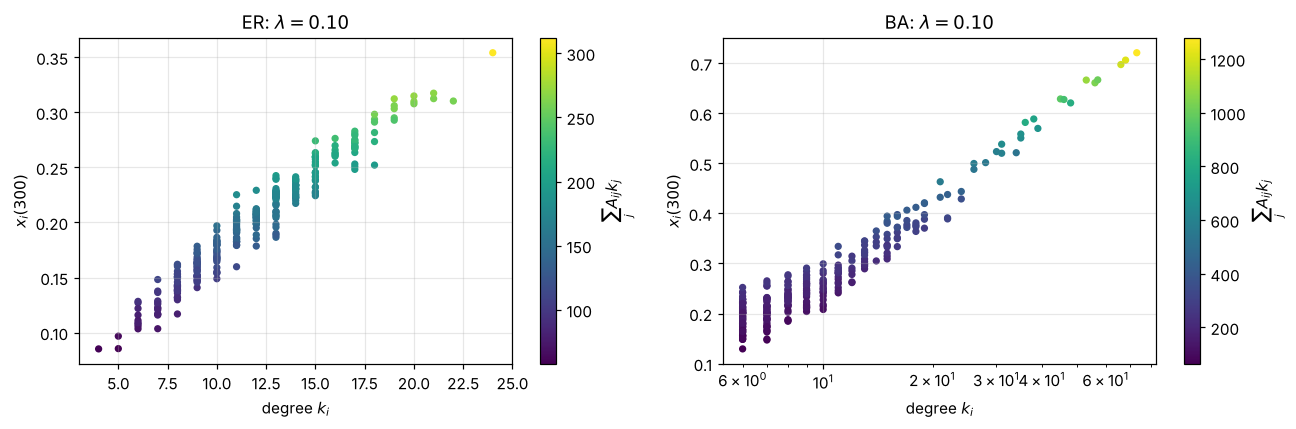

ER: five most infected nodes
    #1: node 179  x = 0.35416  degree = 24  (degree rank 1)
    #2: node  78  x = 0.31743  degree = 21  (degree rank 4)
    #3: node 218  x = 0.31492  degree = 20  (degree rank 5)
    #4: node  75  x = 0.31246  degree = 21  (degree rank 3)
    #5: node  20  x = 0.31230  degree = 19  (degree rank 8)
    degree classes with ≥3 nodes: 15;  largest within-class range at k=11 (34 nodes): x ∈ [0.1598, 0.2252]
    mean within-class coefficient of variation = 5.111%
    corr(x, k) = 0.9736;  corr(x, Σ_j A_ij k_j) = 0.9956
BA: five most infected nodes
    #1: node   2  x = 0.72090  degree = 73  (degree rank 1)
    #2: node   1  x = 0.70616  degree = 68  (degree rank 2)
    #3: node   4  x = 0.69726  degree = 66  (degree rank 3)
    #4: node   7  x = 0.66670  degree = 57  (degree rank 4)
    #5: node   6  x = 0.66631  degree = 53  (degree rank 6)
    degree classes with ≥3 nodes: 15;  largest within-class range at k=6 (78 nodes): x ∈ [0.1294, 0.2521]
    mean within-

In [8]:
LAM_C = 0.10
final_x = {}
for g, A in graphs.items():
    xT, _, _ = rk4_march(sis_field(A, [LAM_C]), np.full((1, NODES), 0.01), 300, DT_SIS)
    final_x[g] = xT[0]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, g in zip(axes, graphs):
    k, x = degrees[g], final_x[g]
    nbr_load = graphs[g] @ k  # sum of neighbour degrees
    sc = ax.scatter(k, x, c=nbr_load, cmap="viridis", s=14)
    plt.colorbar(sc, ax=ax, label=r"$\sum_j A_{ij}k_j$")
    ax.set_xlabel("degree $k_i$"); ax.set_ylabel(r"$x_i(300)$"); ax.set_title(fr"{g}: $\lambda=0.10$")
    if g == "BA":
        ax.set_xscale("log")
plt.tight_layout(); plt.show()

for g in graphs:
    k, x = degrees[g], final_x[g]
    order = np.lexsort((np.arange(NODES), -x))[:5]
    print(f"{g}: five most infected nodes")
    for r_, i in enumerate(order, 1):
        print(f"    #{r_}: node {i:3d}  x = {x[i]:.5f}  degree = {int(k[i])}  (degree rank {np.where(degree_rank(k)==i)[0][0]+1})")
    # spread within degree classes
    spreads = []
    for kv in np.unique(k):
        members = x[k == kv]
        if len(members) >= 3:
            spreads.append((kv, len(members), members.min(), members.max(), members.std() / members.mean()))
    spreads = np.array(spreads)
    worst = spreads[np.argmax(spreads[:, 3] - spreads[:, 2])]
    print(f"    degree classes with ≥3 nodes: {len(spreads)};  largest within-class range at k={int(worst[0])}"
          f" ({int(worst[1])} nodes): x ∈ [{worst[2]:.4f}, {worst[3]:.4f}]")
    print(f"    mean within-class coefficient of variation = {spreads[:,4].mean():.3%}")
    print(f"    corr(x, k) = {np.corrcoef(x, k)[0,1]:.4f};  corr(x, Σ_j A_ij k_j) = {np.corrcoef(x, graphs[g] @ k)[0,1]:.4f}")

**Observations 1(c).**
* Infection probability increases strongly with degree: corr$(x,k)=0.97$ (ER) and $0.94$ (BA). In BA the five most infected nodes are hubs (degrees 73, 68, 66, 57, 53) with $x\approx0.67$–$0.72$. In ER they have degrees 24, 21, 20, 21, 19.
* The ranking is **not** strictly by degree. In ER the 8th-highest-degree node is in the top five, and node 78 (degree rank 4) beats node 75 (rank 3). In BA the 6th-ranked node is fifth.
* Nodes of the same degree do **not** necessarily have the same infection probability. Among the 78 BA nodes with $k=6$, $x$ ranges from $0.13$ to $0.25$, almost a factor of two. Among ER nodes with $k=11$ it ranges from $0.16$ to $0.23$. The colour (sum of neighbour degrees) explains most of this: corr$(x,\sum_jA_{ij}k_j)$ is $0.996$ (ER) and $0.957$ (BA). A node attached to hubs receives much more infection pressure than a node with the same degree whose neighbours are peripheral. In the mean-field equations $x_i$ depends on $\sum_j A_{ij}x_j$, i.e. on *who* the neighbours are, not just how many there are.

## 1(d) Protection of 10% of the nodes (30 nodes)
A protected node keeps its place in the network ($N=300$ still divides $\rho$), but all its incident edges are removed and $x_i(0)=0$.
* **Targeted:** the 30 highest-degree nodes of the *original* network (ties → smaller index).
* **Random:** 30 nodes drawn uniformly without replacement. 20 independent draws (generator seed 2024) are integrated together as one stacked batch $(20, 51, N)$.

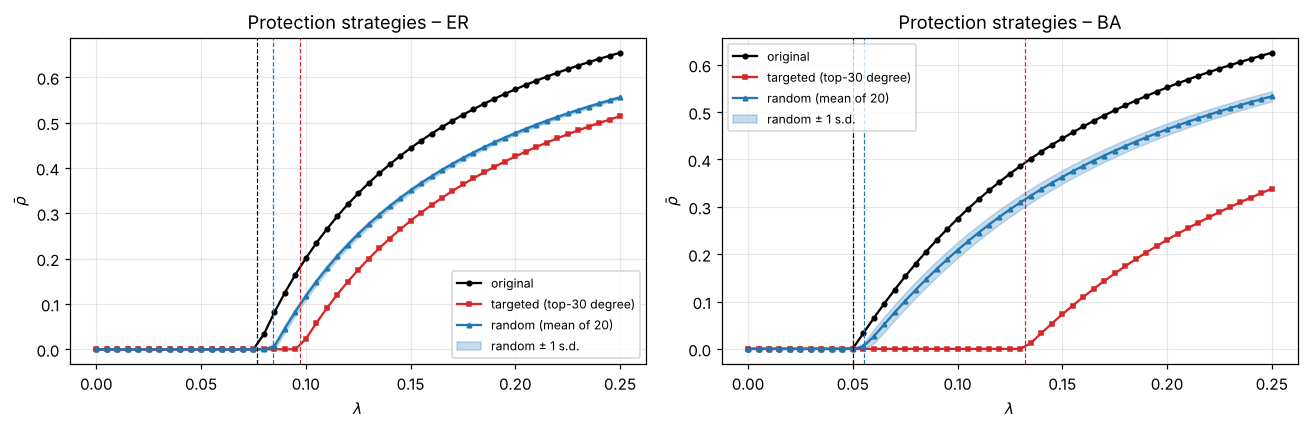

net     strategy            Λmax    1/Λmax  onset(sweep)    ρ̄(λ=0.10)    ρ̄(λ=0.25)
ER      original          13.026    0.0768         0.080        0.2008        0.6541
ER      targeted          10.310    0.0970         0.100        0.0225        0.5141
ER        random   11.849±0.143    0.0844    0.087±0.002   0.1173±0.0076   0.5557±0.0033
BA      original          19.977    0.0501         0.055        0.2748        0.6254
BA      targeted           7.570    0.1321         0.135        0.0000        0.3382
BA        random   18.100±0.874    0.0554    0.058±0.004   0.2086±0.0163   0.5334±0.0106


In [9]:
N_PROTECT, N_DRAWS = 30, 20


def isolate(A, nodes):
    B = A.copy(); B[nodes, :] = 0.0; B[:, nodes] = 0.0
    return B


picker = np.random.default_rng(2024)
protect_out = {}
for g, A in graphs.items():
    hubs = degree_rank(degrees[g])[:N_PROTECT]
    A_hub = isolate(A, hubs)
    x0_hub = np.full(NODES, 0.01); x0_hub[hubs] = 0.0
    avg_hub, _, pers_hub = sis_sweep(A_hub, lam_grid, x0_hub, 300)

    picks = [picker.choice(NODES, N_PROTECT, replace=False) for _ in range(N_DRAWS)]
    A_rand = np.stack([isolate(A, s) for s in picks])
    x0_rand = np.full((N_DRAWS, 1, NODES), 0.01)
    for d, s in enumerate(picks):
        x0_rand[d, 0, s] = 0.0
    avg_rand, _, pers_rand = sis_sweep(A_rand, lam_grid, x0_rand, 300)  # shape (20, 51)
    L_rand = np.array([top_eigenvalue(M) for M in A_rand])
    protect_out[g] = dict(hubs=hubs, avg_hub=avg_hub, pers_hub=pers_hub, L_hub=top_eigenvalue(A_hub),
                          avg_rand=avg_rand, pers_rand=pers_rand, L_rand=L_rand)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, g in zip(axes, graphs):
    o = protect_out[g]
    ax.plot(lam_grid, sweep_b[g][0], "k-o", ms=3, label="original")
    ax.plot(lam_grid, o["avg_hub"], "-s", ms=3, color="tab:red", label="targeted (top-30 degree)")
    mu_r, sd_r = o["avg_rand"].mean(0), o["avg_rand"].std(0)
    ax.plot(lam_grid, mu_r, "-^", ms=3, color="tab:blue", label="random (mean of 20)")
    ax.fill_between(lam_grid, mu_r - sd_r, mu_r + sd_r, color="tab:blue", alpha=0.25, label="random ± 1 s.d.")
    for L, c in ((top_eigenvalue(graphs[g]), "k"), (o["L_hub"], "tab:red"), (o["L_rand"].mean(), "tab:blue")):
        ax.axvline(1 / L, color=c, ls="--", lw=0.8)
    ax.set_xlabel(r"$\lambda$"); ax.set_ylabel(r"$\bar\rho$"); ax.set_title(f"Protection strategies – {g}")
    ax.legend()
plt.tight_layout(); plt.show()

print(f"{'net':4s}{'strategy':>12s}{'Λmax':>16s}{'1/Λmax':>10s}{'onset(sweep)':>14s}{'ρ̄(λ=0.10)':>14s}{'ρ̄(λ=0.25)':>14s}")
i10, i25 = np.argmin(abs(lam_grid - 0.10)), np.argmin(abs(lam_grid - 0.25))
for g in graphs:
    o = protect_out[g]; avg0, _, pers0 = sweep_b[g]
    L0 = top_eigenvalue(graphs[g])
    on = lambda p: lam_grid[np.argmax(p)] if p.any() else np.nan
    print(f"{g:4s}{'original':>12s}{L0:16.3f}{1/L0:10.4f}{on(pers0):14.3f}{avg0[i10]:14.4f}{avg0[i25]:14.4f}")
    print(f"{g:4s}{'targeted':>12s}{o['L_hub']:16.3f}{1/o['L_hub']:10.4f}{on(o['pers_hub']):14.3f}{o['avg_hub'][i10]:14.4f}{o['avg_hub'][i25]:14.4f}")
    onsets = np.array([on(p) for p in o["pers_rand"]])
    print(f"{g:4s}{'random':>12s}{o['L_rand'].mean():9.3f}±{o['L_rand'].std():5.3f}{np.mean(1/o['L_rand']):10.4f}"
          f"{np.nanmean(onsets):9.3f}±{np.nanstd(onsets):.3f}"
          f"{o['avg_rand'][:, i10].mean():9.4f}±{o['avg_rand'][:, i10].std():.4f}"
          f"{o['avg_rand'][:, i25].mean():9.4f}±{o['avg_rand'][:, i25].std():.4f}")

**Observations 1(d).**
* **Targeted protection** cuts $\Lambda_{max}$ from $13.03\to10.31$ (ER) and $19.98\to7.57$ (BA). The threshold rises accordingly to $1/\Lambda=0.097$ and $0.132$, and the sweeps give onsets of $0.100$ and $0.135$, consistent with this.
* **Random protection** of the same number of nodes barely changes the spectrum: $\Lambda_{max}=11.85\pm0.14$ (ER) and $18.10\pm0.87$ (BA), with onsets $0.087$ and $0.058$.
* At $\lambda=0.10$ the BA network is endemic under random protection ($\bar\rho=0.21$) but infection-free under targeted protection. At $\lambda=0.25$, targeted protection still roughly halves $\bar\rho$ in BA ($0.63\to0.34$).
* The difference is much larger for BA than for ER. In BA a few hubs carry most of the edges and most of the weight of the principal eigenvector, so removing them breaks the backbone of transmission. In ER, degrees are concentrated around $\langle k\rangle\approx12$, so the top 30 nodes are not much more important than average ones, and targeted protection is only moderately better than random.

---
# Question 2 — SIR dynamics

$$\dot S_i=-\lambda S_i\sum_jA_{ij}I_j,\quad \dot I_i=\lambda S_i\sum_jA_{ij}I_j-\mu I_i,\quad \dot R_i=\mu I_i .$$

The state array has shape $(\text{batch},3,N)$. All three compartments are integrated (rather than eliminating $R=1-S-I$) so that conservation can be *checked*, not assumed. RK4, $\Delta t=0.02$.

**Stopping rule:** integrate in blocks of 300 time units, starting with $[0,300]$, until $\max_i I_i(t)<10^{-8}$ for every member of the batch. Each member's stopping time $T$ is the first grid time at which its own $\max_i I_i<10^{-8}$; $R_{final}=R(T)$.

In [10]:
DT_SIR = 0.02


def sir_field(A, lam, mu=MU):
    rate = np.asarray(lam, float).reshape(-1, 1)

    def f(Y):
        S, I = Y[:, 0], Y[:, 1]
        push = rate * S * (I @ A)
        out = np.empty_like(Y)
        out[:, 0] = -push; out[:, 1] = push - mu * I; out[:, 2] = mu * I
        return out
    return f


def sir_probe(Y):
    S, I, R = Y[:, 0], Y[:, 1], Y[:, 2]
    return np.stack([S.mean(-1), I.mean(-1), R.mean(-1), I.max(-1),
                     Y.min(axis=(1, 2)), Y.max(axis=(1, 2)), np.abs(S + I + R - 1).max(-1)], axis=-1)


def sir_run(A, lams, Y0, dt=DT_SIR, block=300.0, tol=1e-8, t_cap=30000.0, every=1):
    """Integrates blockwise until max_i I_i < tol for every batch member.
    Returns dict with time grid, S,I,R means, stopping times and conservation diagnostics."""
    field = sir_field(A, lams)
    y, t_start, ts_all, rec_all = np.array(Y0, float), 0.0, [], []
    while True:
        y, ts, rec = rk4_march(field, y, t_start + block, dt, probe=sir_probe, every=every, t0=t_start)
        if t_start > 0:
            ts, rec = ts[1:], rec[1:]
        ts_all.append(ts); rec_all.append(rec)
        t_start += block
        if np.all(rec[-1, :, 3] < tol) or t_start >= t_cap:
            break
    ts = np.concatenate(ts_all); rec = np.concatenate(rec_all)  # rec: (time, batch, 7)
    below = rec[:, :, 3] < tol
    stop_idx = np.where(below.any(0), below.argmax(0), len(ts) - 1)
    Imean = rec[:, :, 1]
    peak_idx = Imean.argmax(0)  # argmax returns the earliest maximiser
    b = np.arange(Imean.shape[1])
    return dict(t=ts, S=rec[:, :, 0], I=Imean, R=rec[:, :, 2], T=ts[stop_idx],
                Ipeak=Imean[peak_idx, b], tpeak=ts[peak_idx], Rfinal=rec[stop_idx, b, 2],
                minval=rec[:, :, 4].min(0), maxval=rec[:, :, 5].max(0), cons=rec[:, :, 6].max(0))


def sir_initial(n_batch, infected_sets, immune_sets=None):
    Y0 = np.zeros((n_batch, 3, NODES)); Y0[:, 0] = 1.0
    for b, seeds in enumerate(infected_sets):
        Y0[b, 0, seeds] = 0.0; Y0[b, 1, seeds] = 1.0
    if immune_sets is not None:
        for b, imm in enumerate(immune_sets):
            Y0[b, 0, imm] = 0.0; Y0[b, 1, imm] = 0.0; Y0[b, 2, imm] = 1.0
    return Y0


top3 = {g: degree_rank(degrees[g])[:3] for g in graphs}
for g in graphs:
    print(f"{g}: initially infected (3 highest degree) = {top3[g]}, degrees {degrees[g][top3[g]].astype(int)}")

ER: initially infected (3 highest degree) = [179 156  75], degrees [24 22 21]
BA: initially infected (3 highest degree) = [2 1 4], degrees [73 68 66]


## 2(a) Aggregate curves $S(t), I(t), R(t)$ for $\lambda = 0.04, 0.08, 0.12, 0.20$

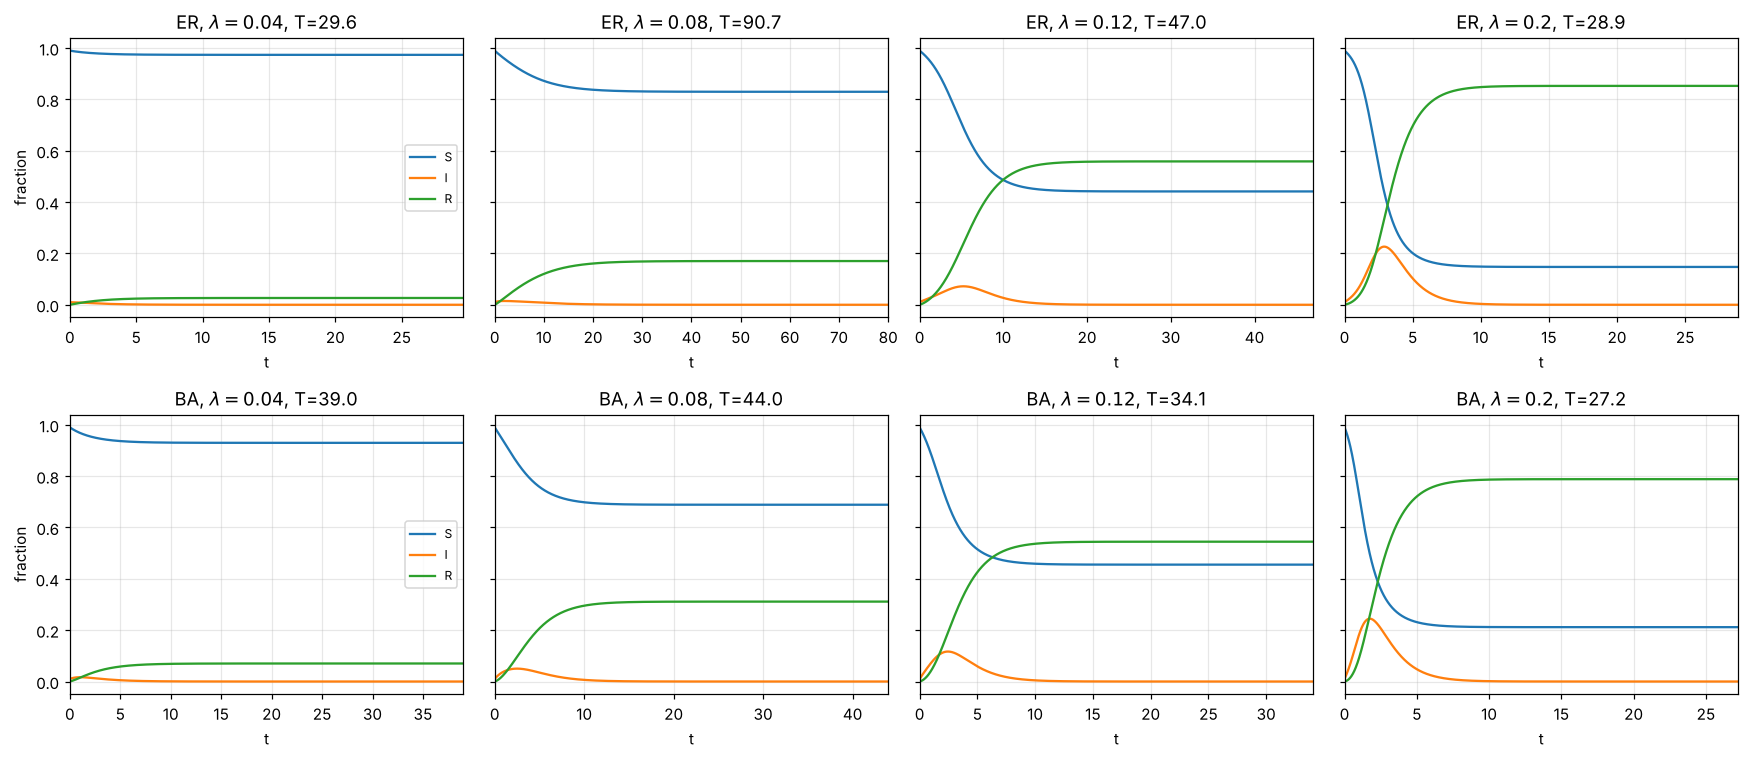

net      λ  T (max I<1e-8)   max|S+I+R-1|    min entry    max entry    Ipeak   tpeak   Rfinal
ER    0.04           29.64       9.99e-15     0.00e+00     1.000000   0.0100    0.00   0.0264
ER    0.08           90.66       1.69e-14     0.00e+00     1.000000   0.0148    1.96   0.1703
ER    0.12           47.00       9.33e-15     0.00e+00     1.000000   0.0719    5.22   0.5585
ER    0.20           28.88       6.44e-15     0.00e+00     1.000000   0.2264    2.92   0.8527
BA    0.04           39.00       1.15e-14     0.00e+00     1.000000   0.0167    1.02   0.0702
BA    0.08           43.98       9.99e-15     0.00e+00     1.000000   0.0502    2.50   0.3113
BA    0.12           34.06       7.55e-15     0.00e+00     1.000000   0.1167    2.44   0.5447
BA    0.20           27.22       6.11e-15     0.00e+00     1.000000   0.2447    1.74   0.7883


In [11]:
lam_sir_a = np.array([0.04, 0.08, 0.12, 0.20])
sir_a = {}
fig, axes = plt.subplots(2, 4, figsize=(16, 7), sharey=True)
for row, (g, A) in enumerate(graphs.items()):
    res = sir_run(A, lam_sir_a, sir_initial(4, [top3[g]] * 4))
    sir_a[g] = res
    for j, lam in enumerate(lam_sir_a):
        ax = axes[row, j]; Tj = res["T"][j]; m = res["t"] <= Tj
        ax.plot(res["t"][m], res["S"][m, j], label="S"); ax.plot(res["t"][m], res["I"][m, j], label="I")
        ax.plot(res["t"][m], res["R"][m, j], label="R")
        ax.set_title(fr"{g}, $\lambda={lam}$, T={Tj:.1f}"); ax.set_xlabel("t")
        ax.set_xlim(0, min(Tj, 80))
        if j == 0: ax.set_ylabel("fraction"); ax.legend()
plt.tight_layout(); plt.show()

print(f"{'net':4s}{'λ':>6s}{'T (max I<1e-8)':>16s}{'max|S+I+R-1|':>15s}{'min entry':>13s}{'max entry':>13s}{'Ipeak':>9s}{'tpeak':>8s}{'Rfinal':>9s}")
for g, res in sir_a.items():
    for j, lam in enumerate(lam_sir_a):
        print(f"{g:4s}{lam:6.2f}{res['T'][j]:16.2f}{res['cons'][j]:15.2e}{res['minval'][j]:13.2e}"
              f"{res['maxval'][j]:13.6f}{res['Ipeak'][j]:9.4f}{res['tpeak'][j]:8.2f}{res['Rfinal'][j]:9.4f}")

**Observations 2(a).**
* The SIR threshold in this approximation is again $\lambda\Lambda_{max}=1$ (growth of $I$ while $S\approx1$). ER at $\lambda=0.04$ ($\lambda\Lambda=0.52$) is subcritical: $I$ only decays from its initial value, so $t_{peak}=0$ and $R_{final}=0.026$. The three seeds and some of their neighbours recover.
* ER at $\lambda=0.08$ ($\lambda\Lambda=1.04$) is barely supercritical. The outbreak is small ($R_{final}=0.17$) and slow: it needs $T\approx91$ to reach $\max_iI_i<10^{-8}$.
* For larger $\lambda$ the outbreaks are fast and large: $R_{final}=0.56$ and $0.85$ (ER), $0.54$ and $0.79$ (BA).
* BA reacts earlier (a larger $R_{final}$ at $\lambda=0.04$ and $0.08$) because the seeds are huge hubs. At $\lambda=0.20$, however, ER ends with a *larger* final size, because many low-degree BA nodes escape infection.
* Conservation $S_i+I_i+R_i=1$ holds to $\le2\times10^{-14}$, and all entries stay exactly inside $[0,1]$.

**Note on the time window.** Every run reaches $\max_i I_i<10^{-8}$ inside the first block $[0,300]$, so $T$ above is the first grid time at which the criterion holds. The plots are cropped to $t\le80$ because nothing happens after that. **Conservation:** $\max|S_i+I_i+R_i-1|$ stays at machine precision, as expected since RK4 preserves linear invariants exactly. All entries stay inside $[0,1]$ (minimum $\ge -10^{-15}$ level).

**Accuracy check:** representative runs repeated with $\Delta t=0.005$ and with DOP853 (`rtol=1e-10`).

In [12]:
def sir_rhs_scipy(A, lam, mu=MU):
    def f(t, y):
        S, I = y[:NODES], y[NODES:2 * NODES]
        push = lam * S * (A @ I)
        return np.concatenate([-push, push - mu * I, mu * I])
    return f


print(f"{'net':4s}{'λ':>6s}{'max|I(dt=.02)-I(dt=.005)|':>28s}{'max|I(dt=.02)-I(DOP853)|':>27s}{'|ΔRfinal| vs DOP853':>21s}")
for g, A in graphs.items():
    res = sir_a[g]
    fine = sir_run(A, lam_sir_a, sir_initial(4, [top3[g]] * 4), dt=0.005, every=4)
    for j, lam in enumerate(lam_sir_a):
        Tj = res["t"][-1]
        ref = solve_ivp(sir_rhs_scipy(A, lam), (0, Tj), sir_initial(1, [top3[g]])[0].ravel(),
                        method="DOP853", rtol=1e-10, atol=1e-12, t_eval=res["t"])
        I_ref = ref.y[NODES:2 * NODES].mean(0); R_ref = ref.y[2 * NODES:].mean(0)
        n = min(len(fine["t"]), len(res["t"]))
        e1 = np.max(np.abs(res["I"][:n, j] - fine["I"][:n, j]))
        e2 = np.max(np.abs(res["I"][:, j] - I_ref))
        e3 = abs(res["Rfinal"][j] - R_ref[np.searchsorted(res["t"], res["T"][j])])
        print(f"{g:4s}{lam:6.2f}{e1:28.2e}{e2:27.2e}{e3:21.2e}")

net      λ   max|I(dt=.02)-I(dt=.005)|   max|I(dt=.02)-I(DOP853)|  |ΔRfinal| vs DOP853


ER    0.04                    4.16e-12                   4.28e-12             7.66e-13


ER    0.08                    4.71e-12                   1.69e-11             8.71e-12


ER    0.12                    9.84e-12                   1.01e-11             5.05e-12


ER    0.20                    5.89e-10                   5.93e-10             1.85e-11


BA    0.04                    1.73e-11                   1.75e-11             3.22e-12


BA    0.08                    1.34e-11                   1.35e-11             9.83e-12


BA    0.12                    1.73e-11                   1.02e-10             1.28e-11


BA    0.20                    1.03e-09                   1.04e-09             7.13e-12


## 2(b) Sweep $\lambda\in[0,0.25]$: $I_{peak}$, $t_{peak}$, $R_{final}$

ER: stopping times range 18.4 – 90.7;  max conservation error 1.8e-14


BA: stopping times range 18.4 – 50.0;  max conservation error 1.2e-14


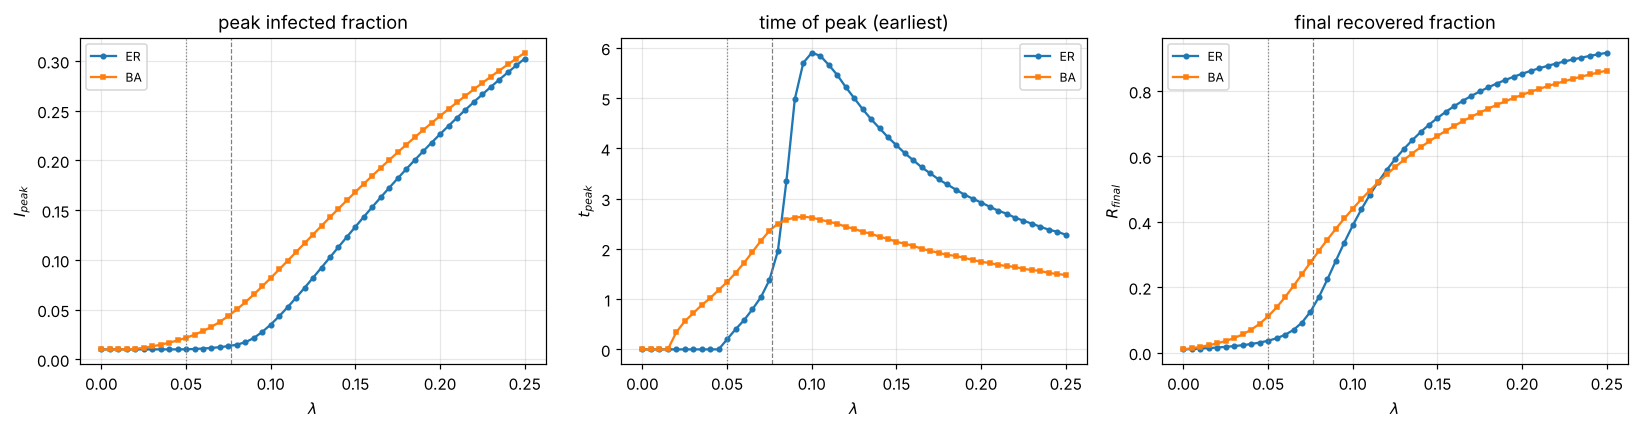

In [13]:
sir_b = {}
for g, A in graphs.items():
    sir_b[g] = sir_run(A, lam_grid, sir_initial(len(lam_grid), [top3[g]] * len(lam_grid)))
    print(f"{g}: stopping times range {sir_b[g]['T'].min():.1f} – {sir_b[g]['T'].max():.1f};"
          f"  max conservation error {sir_b[g]['cons'].max():.1e}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for g, mk in (("ER", "o"), ("BA", "s")):
    r = sir_b[g]
    axes[0].plot(lam_grid, r["Ipeak"], mk + "-", ms=3, label=g)
    axes[1].plot(lam_grid, r["tpeak"], mk + "-", ms=3, label=g)
    axes[2].plot(lam_grid, r["Rfinal"], mk + "-", ms=3, label=g)
for ax, lab in zip(axes, [r"$I_{peak}$", r"$t_{peak}$", r"$R_{final}$"]):
    for g, ls in (("ER", "--"), ("BA", ":")):
        ax.axvline(lam_ref[g], color="gray", ls=ls, lw=0.8)
    ax.set_xlabel(r"$\lambda$"); ax.set_ylabel(lab); ax.legend()
axes[0].set_title("peak infected fraction"); axes[1].set_title("time of peak (earliest)"); axes[2].set_title("final recovered fraction")
plt.tight_layout(); plt.show()

**Observations 2(b).**
* $I_{peak}$ and $R_{final}$ stay near their seed-only values ($3/N=0.01$) below threshold and grow steadily above it. The BA curves start rising earlier ($\lambda_{ref}=0.050$ versus $0.077$ for ER).
* The $R_{final}$ curves cross near $\lambda\approx0.11$. Above that, ER reaches a larger final size, because its homogeneous degree distribution leaves fewer weakly connected nodes that escape infection.
* $t_{peak}$ is $0$ below threshold, where the maximum of $I(t)$ is the initial value. It jumps up and peaks just above threshold (about $t\approx6$ for ER near $\lambda\approx0.10$), then decreases as $\lambda$ grows. This is again critical slowing down: near threshold the epidemic grows at rate $\lambda\Lambda_{max}-\mu\approx0$. For BA, starting from the hubs, the peak is always early ($t_{peak}\lesssim2.7$).

**Peak-estimate convergence.** For selected $\lambda$ the sweep is repeated with output sampling (= step) $\Delta t=0.005$ and $0.001$. The peak is also refined by fitting a parabola through the three samples around the discrete maximum.

In [14]:
def parabolic_peak(t, y, i):
    if i == 0 or i == len(y) - 1:
        return t[i], y[i]
    y0, y1, y2 = y[i - 1], y[i], y[i + 1]; h = t[i + 1] - t[i]
    denom = y0 - 2 * y1 + y2
    shift = 0.5 * (y0 - y2) / denom if denom != 0 else 0.0
    return t[i] + shift * h, y1 - 0.25 * (y0 - y2) * shift


check_l = np.array([0.08, 0.12, 0.20])
print(f"{'net':4s}{'λ':>6s}{'dt':>7s}{'Ipeak':>12s}{'tpeak':>10s}{'tpeak(parab.)':>15s}{'Rfinal':>10s}")
for g, A in graphs.items():
    for dt in (0.02, 0.005, 0.001):
        r = sir_run(A, check_l, sir_initial(3, [top3[g]] * 3), dt=dt, block=60.0)
        for j, lam in enumerate(check_l):
            tp, _ = parabolic_peak(r["t"], r["I"][:, j], np.argmax(r["I"][:, j]))
            print(f"{g:4s}{lam:6.2f}{dt:7.3f}{r['Ipeak'][j]:12.7f}{r['tpeak'][j]:10.3f}{tp:15.4f}{r['Rfinal'][j]:10.6f}")

net      λ     dt       Ipeak     tpeak  tpeak(parab.)    Rfinal


ER    0.08  0.020   0.0147706     1.960         1.9668  0.170297
ER    0.12  0.020   0.0719424     5.220         5.2274  0.558511
ER    0.20  0.020   0.2264230     2.920         2.9144  0.852666


ER    0.08  0.005   0.0147706     1.965         1.9667  0.170297
ER    0.12  0.005   0.0719426     5.225         5.2274  0.558511
ER    0.20  0.005   0.2264251     2.915         2.9144  0.852666


ER    0.08  0.001   0.0147706     1.967         1.9667  0.170297
ER    0.12  0.001   0.0719426     5.227         5.2274  0.558511
ER    0.20  0.001   0.2264251     2.914         2.9144  0.852666


BA    0.08  0.020   0.0502056     2.500         2.4994  0.311309
BA    0.12  0.020   0.1167376     2.440         2.4485  0.544696
BA    0.20  0.020   0.2447076     1.740         1.7497  0.788252


BA    0.08  0.005   0.0502056     2.500         2.4994  0.311309
BA    0.12  0.005   0.1167389     2.450         2.4485  0.544696
BA    0.20  0.005   0.2447164     1.750         1.7497  0.788252


BA    0.08  0.001   0.0502056     2.499         2.4994  0.311309
BA    0.12  0.001   0.1167390     2.448         2.4485  0.544696
BA    0.20  0.001   0.2447164     1.750         1.7496  0.788252


**Convergence of the peak estimates.** Going from $\Delta t=0.02$ to $0.001$ changes $I_{peak}$ by less than $10^{-5}$ and $R_{final}$ by less than $10^{-6}$. $t_{peak}$ is only resolved to the sampling interval when the discrete argmax is used. The parabolic refinement agrees to $\sim10^{-3}$ already at $\Delta t=0.02$ and converges to $\sim10^{-4}$. So the reported $t_{peak}$ values are accurate to within the sampling step $\Delta t=0.02$.

## 2(c) Seeding strategies at $\lambda=0.12$
Three highest-degree nodes, three lowest-degree nodes (ties → smaller index), and 30 random triples (generator seed 7). All 32 initial conditions are integrated as one batch.

net    strategy      seed degrees  Σ nbr-deg    Σ v1            Ipeak          tpeak           Rfinal
ER      highest        [24 22 21]        834   0.317           0.0719           5.22           0.5585
ER       lowest           [4 5 5]        180   0.062           0.0670           8.12           0.5623
ER       random       mean k=11.5        446   0.158   0.0695±0.0006    6.48±0.32   0.5613±0.0006
BA      highest        [73 68 66]       3689   0.742           0.1167           2.44           0.5447
BA       lowest           [6 6 6]        435   0.083           0.1123           4.04           0.5518
BA       random       mean k=11.0        680   0.123   0.1129±0.0006    3.79±0.26   0.5517±0.0009


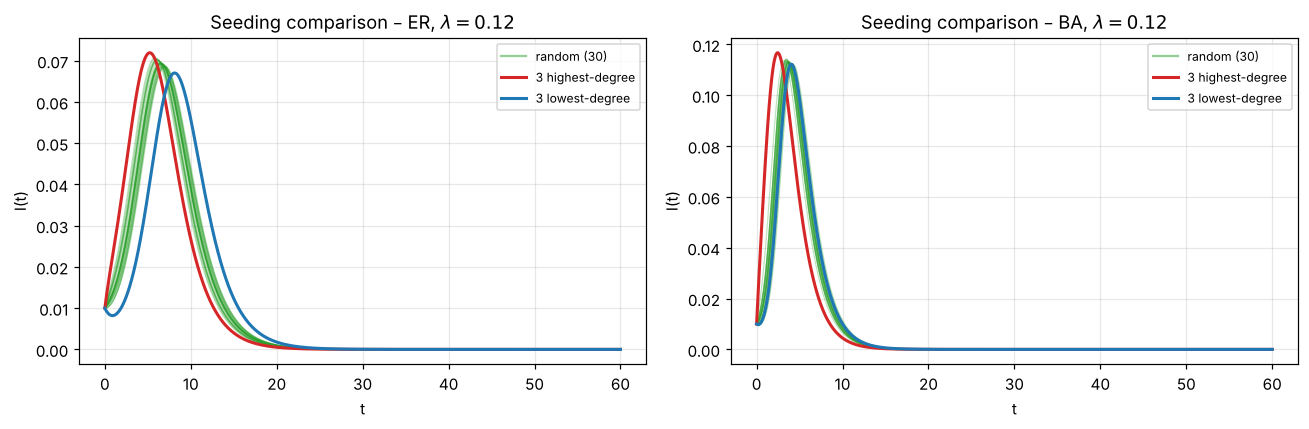

In [15]:
LAM_SIR = 0.12
seed_gen = np.random.default_rng(7)
seeding = {}
for g, A in graphs.items():
    k = degrees[g]
    low3 = degree_rank(k, highest=False)[:3]
    rand_sets = [seed_gen.choice(NODES, 3, replace=False) for _ in range(30)]
    sets = [top3[g], low3] + rand_sets
    r = sir_run(A, np.full(len(sets), LAM_SIR), sir_initial(len(sets), sets))
    seeding[g] = dict(r=r, sets=sets, low3=low3)

# eigenvector centrality (principal eigenvector) to explain seed influence
print(f"{'net':4s}{'strategy':>11s}{'seed degrees':>18s}{'Σ nbr-deg':>11s}{'Σ v1':>8s}{'Ipeak':>17s}{'tpeak':>15s}{'Rfinal':>17s}")
for g, A in graphs.items():
    vals, vecs = np.linalg.eigh(A); v1 = np.abs(vecs[:, -1])
    k = degrees[g]; s = seeding[g]; r = s["r"]
    for name, b in (("highest", 0), ("lowest", 1)):
        seeds = s["sets"][b]
        print(f"{g:4s}{name:>11s}{str(k[seeds].astype(int)):>18s}{(A @ k)[seeds].sum():11.0f}{v1[seeds].sum():8.3f}"
              f"{r['Ipeak'][b]:17.4f}{r['tpeak'][b]:15.2f}{r['Rfinal'][b]:17.4f}")
    rk = np.array([k[x].mean() for x in s["sets"][2:]])
    print(f"{g:4s}{'random':>11s}{'mean k=' + format(rk.mean(), '.1f'):>18s}"
          f"{np.mean([(A @ k)[x].sum() for x in s['sets'][2:]]):11.0f}{np.mean([v1[x].sum() for x in s['sets'][2:]]):8.3f}"
          f"{r['Ipeak'][2:].mean():9.4f}±{r['Ipeak'][2:].std():.4f}"
          f"{r['tpeak'][2:].mean():8.2f}±{r['tpeak'][2:].std():.2f}"
          f"{r['Rfinal'][2:].mean():9.4f}±{r['Rfinal'][2:].std():.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, g in zip(axes, graphs):
    r = seeding[g]["r"]; m = r["t"] <= 60
    for b in range(2, 32):
        ax.plot(r["t"][m], r["I"][m, b], color="tab:green", alpha=0.3, lw=0.8)
    ax.plot([], [], color="tab:green", alpha=0.5, label="random (30)")
    ax.plot(r["t"][m], r["I"][m, 0], color="tab:red", lw=2, label="3 highest-degree")
    ax.plot(r["t"][m], r["I"][m, 1], color="tab:blue", lw=2, label="3 lowest-degree")
    ax.set_xlabel("t"); ax.set_ylabel("I(t)"); ax.set_title(fr"Seeding comparison – {g}, $\lambda=0.12$"); ax.legend()
plt.tight_layout(); plt.show()

**Observations 2(c).**
* **Highest-degree seeding** gives the earliest and highest peak: ER $t_{peak}=5.2$ vs $8.1$ (lowest) vs $6.5\pm0.3$ (random); BA $2.4$ vs $4.0$ vs $3.8\pm0.3$. The seeds' total neighbour degree (834 vs 180 in ER, 3689 vs 435 in BA) and their weight in the principal eigenvector (0.32 vs 0.06 in ER, 0.74 vs 0.08 in BA) show that hub seeds are already in the core of the network. Their infection projects directly onto the fastest-growing mode.
* Low-degree seeds sit on the periphery. The infection first has to travel to the core, which delays the peak and slightly lowers it. Random seeds mostly have average degree and land in between, close to the low-degree case in BA because most BA nodes have low degree.
* **$R_{final}$ is almost independent of the seeding** (0.558–0.562 ER, 0.545–0.552 BA). In this deterministic model a supercritical epidemic always ends with roughly the same final size. Hub seeding even gives a slightly smaller $R_{final}$, because the hubs start in $I$ (not $S$) and do not count as new infections. Randomness in the seed choice causes only very small spread ($\sigma\lesssim10^{-3}$ in $R_{final}$).

## 2(d) Immunization of 30 nodes before the outbreak ($\lambda=0.12$)
Immunized nodes start in $(0,0,1)$ and the network is left unchanged. In each trial the three highest-degree *non-immunized* nodes are infected. Because immunized nodes start in $R$, the protective effect is measured with $R_{additional}=\frac1N\sum_i[R_i(T)-R_i(0)]$. The baseline is the same network with no immunization (top-3 seeding, already computed in 2(c)).

net     strategy             Ipeak   ΔIpeak vs base      R_additional   ΔR_add vs base
ER          none            0.0719                —            0.5585                —
ER      targeted            0.0242            66.4%            0.3061            45.2%
ER        random     0.0459±0.0021            36.2%     0.4232±0.0096            24.2%
     targeted-case seeds: [np.int64(220), np.int64(222), np.int64(239)] (degrees [17 17 17])
BA          none            0.1167                —            0.5447                —
BA      targeted            0.0129            89.0%            0.0813            85.1%
BA        random     0.0853±0.0063            27.0%     0.4314±0.0156            20.8%
     targeted-case seeds: [np.int64(45), np.int64(50), np.int64(80)] (degrees [19 19 19])


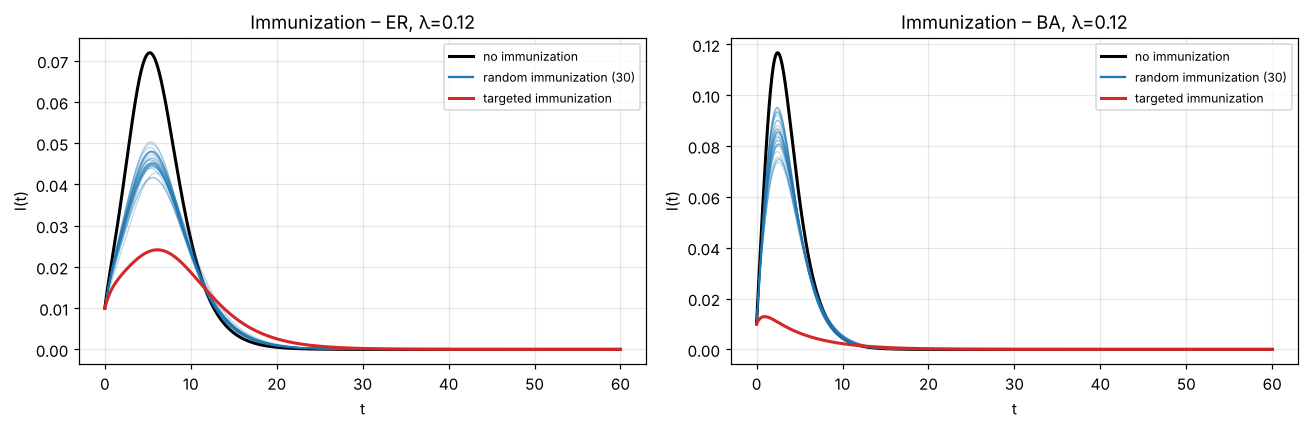

In [16]:
imm_gen = np.random.default_rng(99)
immun = {}
for g, A in graphs.items():
    k = degrees[g]; ranked = degree_rank(k)
    imm_sets = [ranked[:30]] + [imm_gen.choice(NODES, 30, replace=False) for _ in range(30)]
    inf_sets = [[v for v in ranked if v not in set(imm)][:3] for imm in imm_sets]
    Y0 = sir_initial(len(imm_sets), inf_sets, imm_sets)
    r = sir_run(A, np.full(len(imm_sets), LAM_SIR), Y0)
    R_add = r["Rfinal"] - Y0[:, 2].mean(-1)
    immun[g] = dict(r=r, R_add=R_add, inf_sets=inf_sets)

print(f"{'net':4s}{'strategy':>12s}{'Ipeak':>18s}{'ΔIpeak vs base':>17s}{'R_additional':>18s}{'ΔR_add vs base':>17s}")
for g in graphs:
    base_r = seeding[g]["r"]; Ib, Rb = base_r["Ipeak"][0], base_r["Rfinal"][0]
    o = immun[g]; r = o["r"]
    print(f"{g:4s}{'none':>12s}{Ib:18.4f}{'—':>17s}{Rb:18.4f}{'—':>17s}")
    print(f"{g:4s}{'targeted':>12s}{r['Ipeak'][0]:18.4f}{(Ib-r['Ipeak'][0])/Ib:17.1%}{o['R_add'][0]:18.4f}{(Rb-o['R_add'][0])/Rb:17.1%}")
    Ir, Ra = r["Ipeak"][1:], o["R_add"][1:]
    print(f"{g:4s}{'random':>12s}{Ir.mean():11.4f}±{Ir.std():.4f}{(Ib-Ir.mean())/Ib:17.1%}"
          f"{Ra.mean():11.4f}±{Ra.std():.4f}{(Rb-Ra.mean())/Rb:17.1%}")
    print(f"     targeted-case seeds: {o['inf_sets'][0]} (degrees {degrees[g][o['inf_sets'][0]].astype(int)})")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, g in zip(axes, graphs):
    base_r = seeding[g]["r"]; r = immun[g]["r"]; m = r["t"] <= 60; mb = base_r["t"] <= 60
    ax.plot(base_r["t"][mb], base_r["I"][mb, 0], "k", lw=2, label="no immunization")
    for b in range(1, 31):
        ax.plot(r["t"][m], r["I"][m, b], color="tab:blue", alpha=0.3, lw=0.8)
    ax.plot([], [], color="tab:blue", label="random immunization (30)")
    ax.plot(r["t"][m], r["I"][m, 0], color="tab:red", lw=2, label="targeted immunization")
    ax.set_xlabel("t"); ax.set_ylabel("I(t)"); ax.set_title(f"Immunization – {g}, λ=0.12"); ax.legend()
plt.tight_layout(); plt.show()

**Observations 2(d).**
* **Targeted immunization** of the 30 hubs reduces $I_{peak}$ by 66% (ER) and 89% (BA), and $R_{additional}$ by 45% (ER) and 85% (BA). In BA the outbreak almost disappears ($R_{additional}=0.08$).
* **Random immunization** gives much smaller reductions: 36%/24% (ER) and 27%/21% (BA). These are close to what simply removing 10% of the susceptible population would give.
* Immunized hubs act as fire-breaks: they never transmit, and they take away a large share of edges. The SIS analysis showed that removing them lowers $\Lambda_{max}$ strongly, especially in BA.
* With the hubs immunized, the remaining seeds are also less central (degrees 17 in ER and 19 in BA instead of 73, 68, 66 in BA). Part of the reduction comes from this weaker starting point.

---
# Question 3 — Two coupled phase oscillators

$\dot\theta_1=\omega_1+K\sin(\theta_2-\theta_1),\;\dot\theta_2=\omega_2+K\sin(\theta_1-\theta_2)$, with $\omega_1=5,\omega_2=2,\theta_1(0)=0,\theta_2(0)=1$.

Subtracting the two equations gives $\dot\varphi=\Delta\omega-2K\sin\varphi$ with $\Delta\omega=3$. A fixed point (locking) exists iff $2K\ge\Delta\omega$, i.e. $K_c=1.5$; the locked phase is $\varphi^*=\arcsin(\Delta\omega/2K)$. Below $K_c$ the phase slips with period $T_{slip}=2\pi/\sqrt{\Delta\omega^2-4K^2}$. These formulas are used **only as a check** on the simulations.

Phases are integrated unwrapped with RK4, $\Delta t=0.01$, as batches over $K$. Instantaneous frequencies are evaluated from the right-hand side at the sampled states.

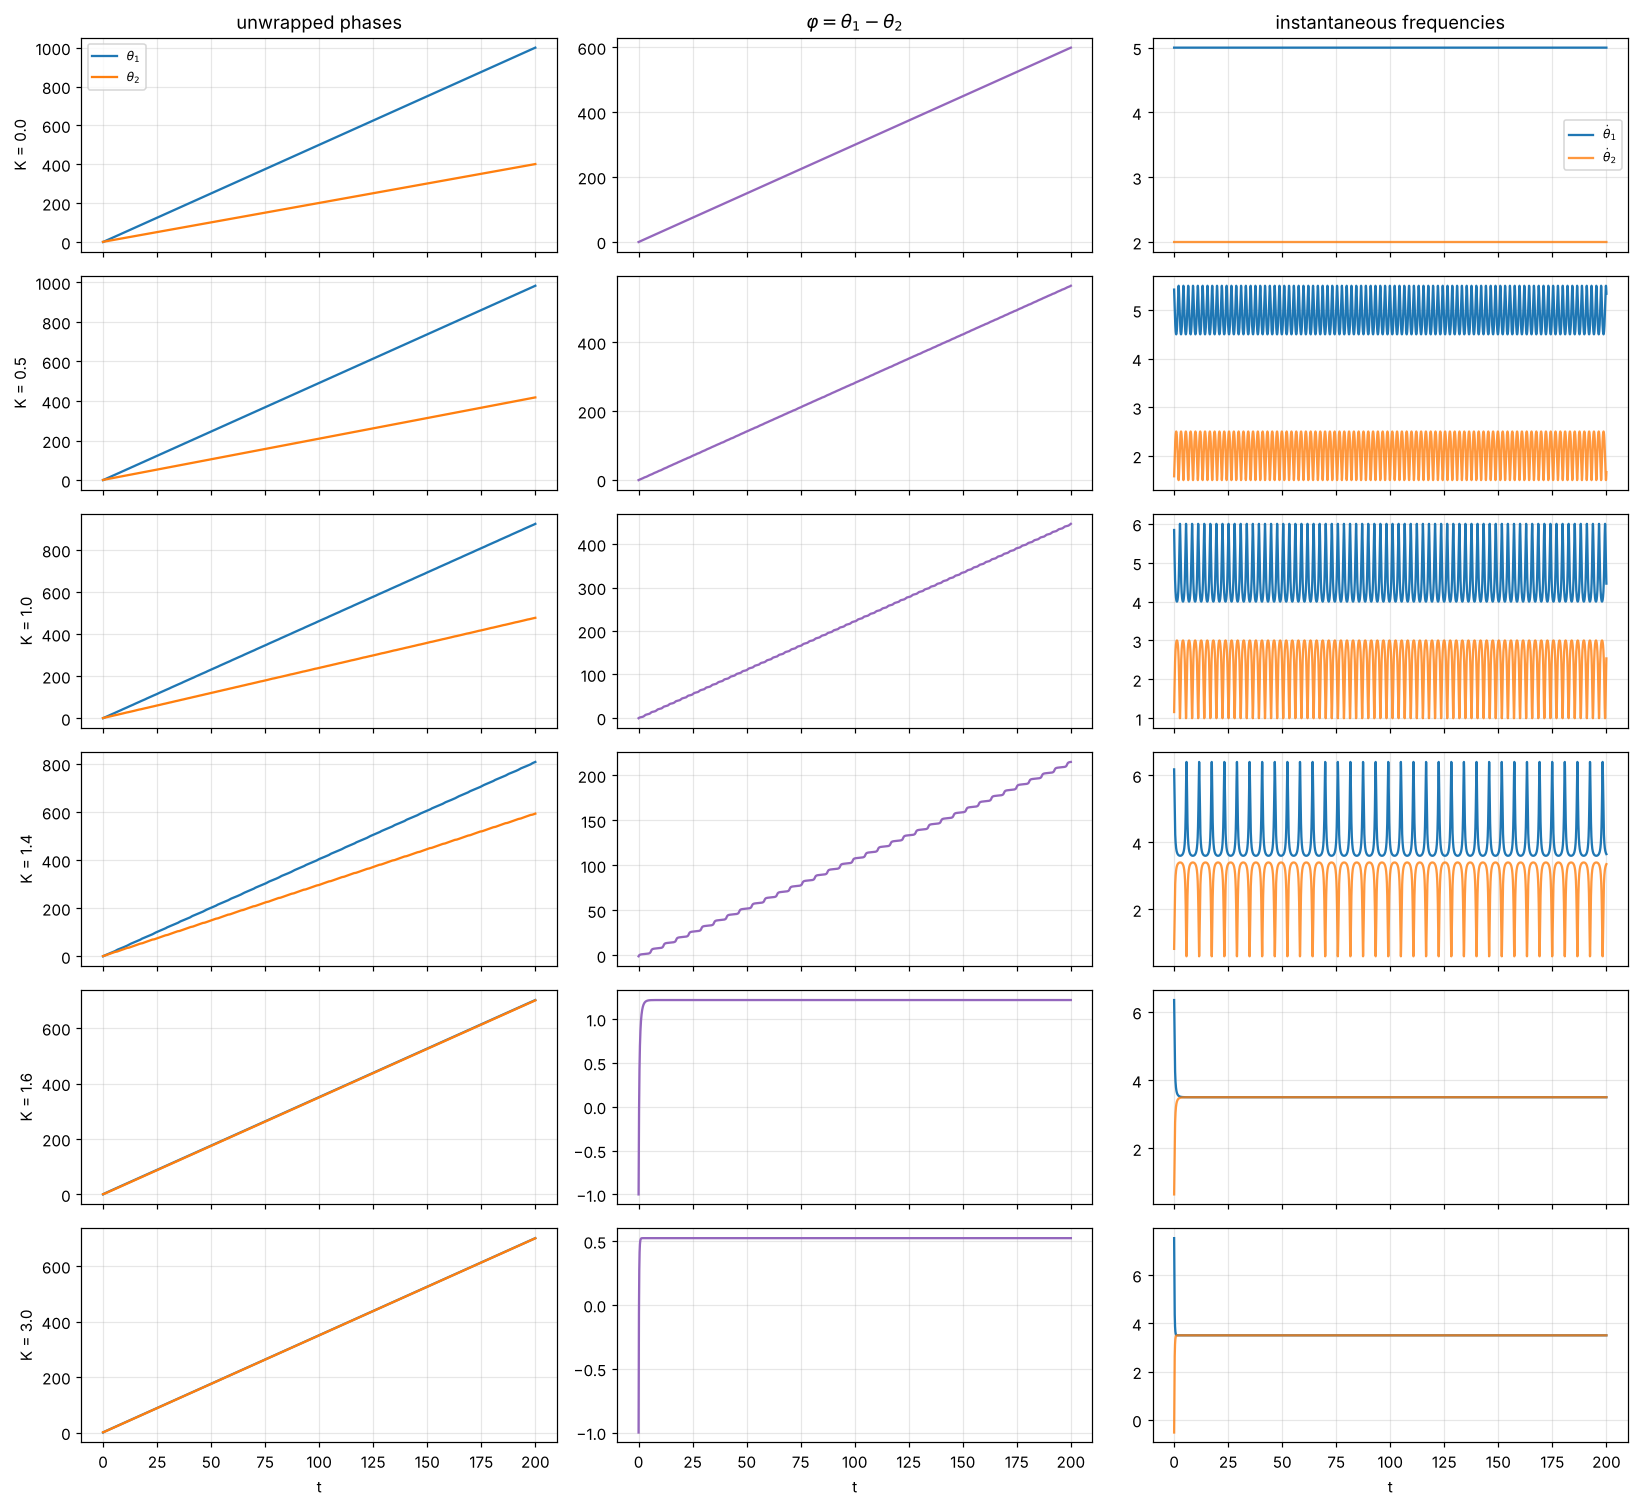

    K       Ω1       Ω2    |Ω1-Ω2|  #2π slips       behaviour  T_slip(meas)  T_slip(theory)
  0.0   5.0000   2.0000   3.00e+00         96     phase slips        2.0944          2.0944
  0.5   4.9144   2.0856   2.83e+00         90     phase slips        2.2213          2.2214
  1.0   4.6241   2.3759   2.25e+00         72     phase slips        2.8100          2.8099
  1.4   4.0360   2.9640   1.07e+00         35     phase slips        5.8338          5.8338
  1.6   3.5000   3.5000   1.07e-14          1    phase-locked           nan             nan
  3.0   3.5000   3.5000   3.55e-15          1    phase-locked           nan             nan



Accuracy: max |θ_RK4(dt=0.01) − θ_DOP853| over all K and t ≤ 200 = 9.15e-07


In [17]:
DT_OSC = 0.01


def pair_field(w1, w2, K):
    w1, w2, K = (np.asarray(v, float) for v in (w1, w2, K))

    def f(Y):
        s = np.sin(Y[:, 1] - Y[:, 0])
        return np.stack([w1 + K * s, w2 - K * s], axis=1)
    return f


def pair_freqs(Y, w1, w2, K):
    s = np.sin(Y[..., 1] - Y[..., 0])
    return w1 + K * s, w2 - K * s


K_a = np.array([0, 0.5, 1, 1.4, 1.6, 3.0])
Y0 = np.tile([0.0, 1.0], (len(K_a), 1))
_, t3, path = rk4_march(pair_field(5.0, 2.0, K_a), Y0, 200, DT_OSC, probe=lambda Y: Y.copy())
f1, f2 = pair_freqs(path, 5.0, 2.0, K_a)
phi = path[..., 0] - path[..., 1]

fig, axes = plt.subplots(len(K_a), 3, figsize=(15, 2.3 * len(K_a)), sharex=True)
for i, K in enumerate(K_a):
    axes[i, 0].plot(t3, path[:, i, 0], label=r"$\theta_1$"); axes[i, 0].plot(t3, path[:, i, 1], label=r"$\theta_2$")
    axes[i, 1].plot(t3, phi[:, i], color="tab:purple")
    axes[i, 2].plot(t3, f1[:, i], label=r"$\dot\theta_1$"); axes[i, 2].plot(t3, f2[:, i], label=r"$\dot\theta_2$", alpha=0.8)
    axes[i, 0].set_ylabel(f"K = {K}")
    if i == 0:
        axes[i, 0].set_title("unwrapped phases"); axes[i, 1].set_title(r"$\varphi=\theta_1-\theta_2$")
        axes[i, 2].set_title("instantaneous frequencies"); axes[i, 0].legend(); axes[i, 2].legend()
for ax in axes[-1]:
    ax.set_xlabel("t")
plt.tight_layout(); plt.show()

i100 = np.searchsorted(t3, 100)
print(f"{'K':>5s}{'Ω1':>9s}{'Ω2':>9s}{'|Ω1-Ω2|':>11s}{'#2π slips':>11s}{'behaviour':>16s}{'T_slip(meas)':>14s}{'T_slip(theory)':>16s}")
for i, K in enumerate(K_a):
    O1 = (path[-1, i, 0] - path[i100, i, 0]) / 100; O2 = (path[-1, i, 1] - path[i100, i, 1]) / 100
    turns = np.floor(phi[:, i] / (2 * np.pi)); slips = int(turns[-1] - turns[0])
    cross = t3[1:][np.diff(turns) != 0]
    Tm = np.diff(cross).mean() if len(cross) > 2 else np.nan
    Tt = 2 * np.pi / np.sqrt(9 - 4 * K**2) if 2 * K < 3 else np.nan
    kind = "phase-locked" if abs(O1 - O2) < 1e-3 else "phase slips"
    print(f"{K:5.1f}{O1:9.4f}{O2:9.4f}{abs(O1-O2):11.2e}{slips:11d}{kind:>16s}{Tm:14.4f}{Tt:16.4f}")

# accuracy check against DOP853
err = 0
for i, K in enumerate(K_a):
    ref = solve_ivp(lambda t, y: [5 + K * np.sin(y[1] - y[0]), 2 + K * np.sin(y[0] - y[1])], (0, 200), [0, 1],
                    method="DOP853", rtol=1e-11, atol=1e-12, t_eval=t3)
    err = max(err, np.abs(ref.y.T - path[:, i]).max())
print(f"\nAccuracy: max |θ_RK4(dt=0.01) − θ_DOP853| over all K and t ≤ 200 = {err:.2e}")

**Observations 3(a).** For $K=0, 0.5, 1, 1.4$ ($K<K_c=1.5$) the phase difference grows without bound. It increases in a staircase pattern, with slow passages (bottlenecks) near $\varphi=\pi/2$, where $\dot\varphi=\Delta\omega-2K\sin\varphi$ is smallest, followed by fast $2\pi$ slips. These are the **phase-slip** cases. The instantaneous frequencies oscillate periodically, and the measured slip periods match $2\pi/\sqrt{\Delta\omega^2-4K^2}$ to $10^{-4}$. For $K=1.6$ and $3$, $\varphi$ settles to a constant, both instantaneous frequencies converge to $(\omega_1+\omega_2)/2=3.5$, and the system is **phase-locked**. The RK4 result agrees with DOP853 to $10^{-6}$ in phase over the whole run.

## 3(b) Mean frequencies vs. $K$ and onset of frequency locking

Coarse grid (ΔK=0.02, T=200): first K with |Ω1−Ω2|<1e-3 is K = 1.50  (analytic K_c = 1.5)


Refined (ΔK=0.001, T=  200): first locked K = 1.500


Refined (ΔK=0.001, T= 1000): first locked K = 1.500


Refined (ΔK=0.001, T= 5000): first locked K = 1.500


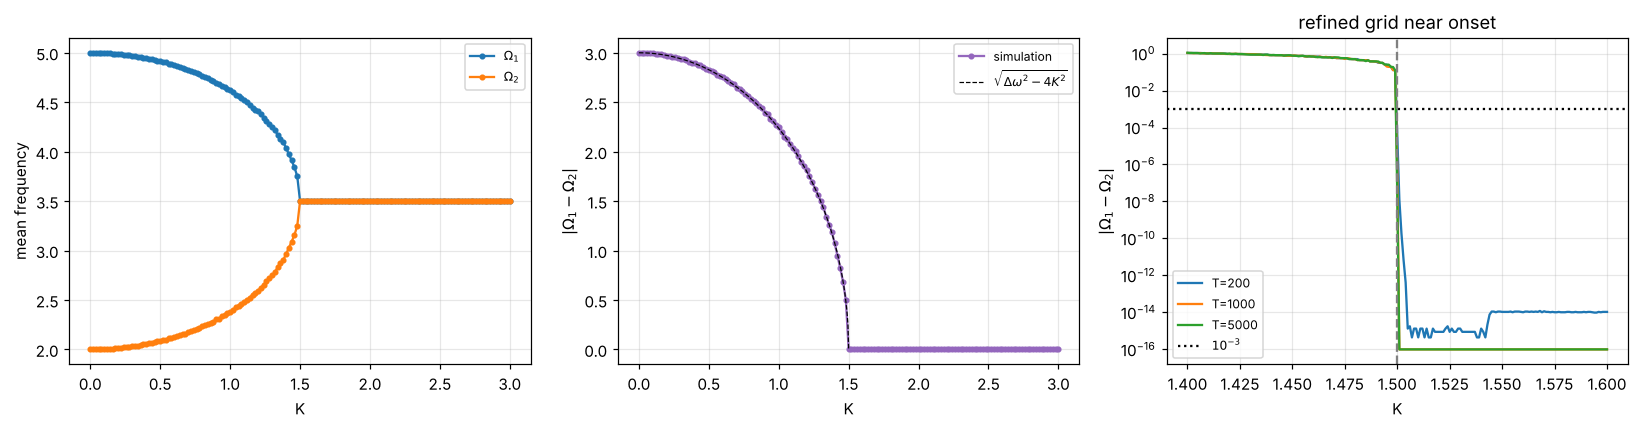

In [18]:
def pair_mean_freqs(K_vals, T_end, window=100.0, w1=5.0, w2=2.0, th2=1.0, dt=DT_OSC):
    Y0 = np.tile([0.0, th2], (len(K_vals), 1))
    field = pair_field(w1, w2, K_vals)
    Ymid, _, _ = rk4_march(field, Y0, T_end - window, dt)
    Yend, _, _ = rk4_march(field, Ymid, T_end, dt, t0=T_end - window)
    return (Yend - Ymid)[:, 0] / window, (Yend - Ymid)[:, 1] / window


K_b = np.round(np.arange(0, 3 + 1e-12, 0.02), 3)
O1, O2 = pair_mean_freqs(K_b, 200)
dO = np.abs(O1 - O2)
K_on = K_b[np.argmax(dO < 1e-3)]
print(f"Coarse grid (ΔK=0.02, T=200): first K with |Ω1−Ω2|<1e-3 is K = {K_on:.2f}  (analytic K_c = 1.5)")

K_f = np.round(np.arange(1.40, 1.60 + 1e-12, 0.001), 4)
onsets = {}
for T_end in (200, 1000, 5000):
    a, b = pair_mean_freqs(K_f, T_end)
    lock = np.abs(a - b) < 1e-3
    onsets[T_end] = (np.abs(a - b), K_f[np.argmax(lock)])
    print(f"Refined (ΔK=0.001, T={T_end:5d}): first locked K = {onsets[T_end][1]:.3f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(K_b, O1, ".-", label=r"$\Omega_1$"); axes[0].plot(K_b, O2, ".-", label=r"$\Omega_2$")
axes[0].set_ylabel("mean frequency"); axes[0].legend()
axes[1].plot(K_b, dO, ".-", color="tab:purple", label="simulation")
Kth = np.linspace(0, 1.5, 300); axes[1].plot(Kth, np.sqrt(9 - 4 * Kth**2), "k--", lw=0.8, label=r"$\sqrt{\Delta\omega^2-4K^2}$")
axes[1].set_ylabel(r"$|\Omega_1-\Omega_2|$"); axes[1].legend()
for T_end, (d, _) in onsets.items():
    axes[2].semilogy(K_f, np.maximum(d, 1e-16), label=f"T={T_end}")
axes[2].axhline(1e-3, color="k", ls=":", label="$10^{-3}$"); axes[2].axvline(1.5, color="gray", ls="--")
axes[2].set_ylabel(r"$|\Omega_1-\Omega_2|$"); axes[2].set_title("refined grid near onset"); axes[2].legend()
for ax in axes:
    ax.set_xlabel("K")
plt.tight_layout(); plt.show()

**Observations 3(b).** Below locking, $\Omega_1$ and $\Omega_2$ approach each other, and $|\Omega_1-\Omega_2|$ follows $\sqrt{\Delta\omega^2-4K^2}$ (square-root law of a saddle-node bifurcation on a circle). Above it they merge at $3.5$. The test $|\Omega_1-\Omega_2|<10^{-3}$ gives the onset $K=1.50$ on the coarse grid. On the refined grid ($\Delta K=0.001$) it gives $K=1.500$ for $T=200$, $1000$ and $5000$, in agreement with $K_c=\Delta\omega/2$. The refined plot shows the finite-time effect just below $K_c$. There the slip period ($2\pi/\sqrt{9-4K^2}$, e.g. $\approx57$ at $K=1.499$) becomes comparable to the averaging window of 100. A window then contains a non-integer number of slips, so $|\Omega_1-\Omega_2|$ is noisy. For $K$ even closer to $K_c$ (slip period $>100$), a short run could falsely report locking. With this grid spacing the result is the same for all three run lengths.

## 3(c) Dependence on the initial phase, $K=1.6$ and $K=3$
Settling time = the earliest grid time after which $|\dot\theta_1-\dot\theta_2|<10^{-3}$ holds for **every** later sample up to $T=200$. If the final sample still violates the bound, the case is reported as "not settled".

   K  θ2(0)  φ(200) mod 2π  φ* theory        Ω1        Ω2  settling t


 1.6      0       1.215375   1.215375   3.50000   3.50000        5.66
 1.6    π/2       1.215375   1.215375   3.50000   3.50000        5.98
 1.6      π       1.215375   1.215375   3.50000   3.50000        6.31
 1.6   3π/2       1.215375   1.215375   3.50000   3.50000        5.98


 3.0      0       0.523599   0.523599   3.50000   3.50000        1.50
 3.0    π/2       0.523599   0.523599   3.50000   3.50000        1.76
 3.0      π       0.523599   0.523599   3.50000   3.50000        2.01
 3.0   3π/2       0.523599   0.523599   3.50000   3.50000        1.76


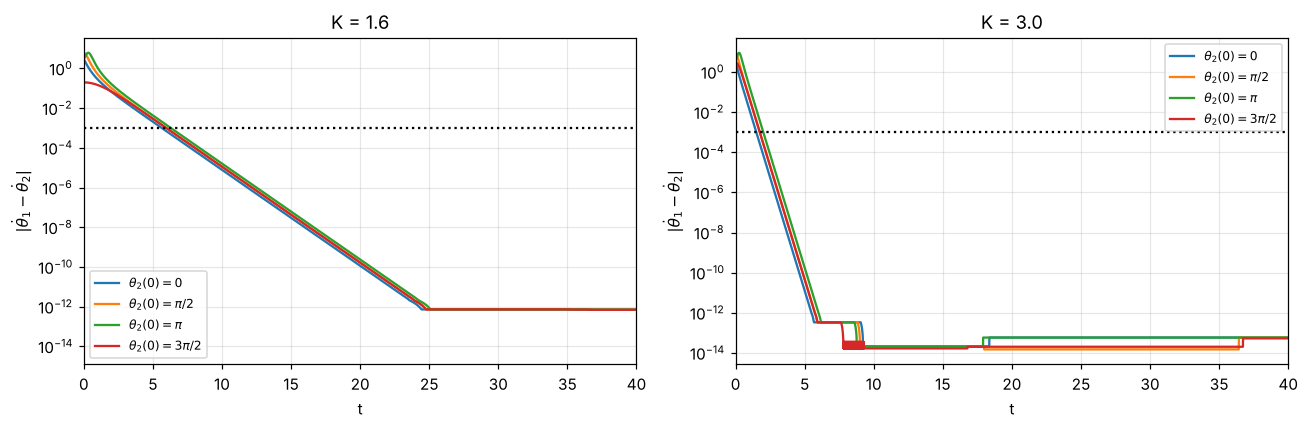

In [19]:
starts = np.array([0, np.pi / 2, np.pi, 3 * np.pi / 2])
labels = ["0", "π/2", "π", "3π/2"]
print(f"{'K':>4s}{'θ2(0)':>7s}{'φ(200) mod 2π':>15s}{'φ* theory':>11s}{'Ω1':>10s}{'Ω2':>10s}{'settling t':>12s}")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, K in zip(axes, (1.6, 3.0)):
    Y0 = np.column_stack([np.zeros(4), starts])
    Kv = np.full(4, K)
    _, tc, pc = rk4_march(pair_field(5.0, 2.0, Kv), Y0, 200, DT_OSC, probe=lambda Y: Y.copy())
    g1, g2 = pair_freqs(pc, 5.0, 2.0, Kv)
    gap = np.abs(g1 - g2)
    i100 = np.searchsorted(tc, 100)
    for j in range(4):
        bad = np.flatnonzero(gap[:, j] >= 1e-3)
        if len(bad) == 0:
            t_set = 0.0
        elif bad[-1] == len(tc) - 1:
            t_set = np.nan
        else:
            t_set = tc[bad[-1] + 1]
        ph_end = np.mod(pc[-1, j, 0] - pc[-1, j, 1], 2 * np.pi)
        W1 = (pc[-1, j, 0] - pc[i100, j, 0]) / 100; W2 = (pc[-1, j, 1] - pc[i100, j, 1]) / 100
        print(f"{K:4.1f}{labels[j]:>7s}{ph_end:15.6f}{np.arcsin(3 / (2 * K)):11.6f}{W1:10.5f}{W2:10.5f}"
              f"{('not settled' if np.isnan(t_set) else f'{t_set:.2f}'):>12s}")
        ax.semilogy(tc, np.maximum(gap[:, j], 1e-16), label=fr"$\theta_2(0)={labels[j]}$")
    ax.axhline(1e-3, color="k", ls=":"); ax.set_xlim(0, 40)
    ax.set_xlabel("t"); ax.set_ylabel(r"$|\dot\theta_1-\dot\theta_2|$"); ax.set_title(f"K = {K}"); ax.legend()
plt.tight_layout(); plt.show()

**Observations 3(c).** Every initial phase ends at the same locked state: $\varphi\bmod2\pi=\arcsin(\Delta\omega/2K)=1.2154$ for $K=1.6$ and $0.5236\,(=\pi/6)$ for $K=3$. The common frequency is $\Omega=3.5$ in all cases. The initial condition only affects the transient. Settling times are $5.7$–$6.3$ for $K=1.6$ and $1.5$–$2.0$ for $K=3$. This reflects the linear relaxation rate $\sqrt{4K^2-\Delta\omega^2}$ ($1.11$ vs $5.20$). Starting at $\theta_2(0)=\pi$ takes longest because $\varphi(0)=-\pi$ is farthest from $\varphi^*$ along the flow. All eight cases settled well within $T=200$, so none had to be reported as unsettled. None of the initial conditions coincides with the unstable fixed point $\pi-\varphi^*$.

## 3(d) Locking range and phase-slip period ($K=1$, $\omega_2=2$, $\omega_1\in[2,6]$)
* Long-time mean frequency difference: $\overline{\Delta\Omega}=[\varphi(T)-\varphi(t_{tr})]/(T-t_{tr})$ with transient $t_{tr}=100$.
* Phase slips: times at which the unwrapped $\varphi$ crosses an integer multiple of $2\pi$ after $t_{tr}$, located on the RK4 grid and refined by linear interpolation. The run is extended in blocks of 200 until at least 6 crossings (≥ 5 complete slips) have been recorded.

Integration extended to T = 300;  minimum # crossings among unlocked cases = 9
Locked for Δω ∈ [0.00, 2.00] → estimated locking range 2.00 < Δω_c ≤ 2.02  (analytic 2K = 2)
Max relative deviation of measured slip period from 2π/√(Δω²−4K²): 1.27e-07
   Δω = 2.02: <ΔΩ> = 0.28280, T_slip(meas) = 22.1591, T_slip(theory) = 22.1591, slips recorded = 8
   Δω = 2.10: <ΔΩ> = 0.63080, T_slip(meas) = 9.8127, T_slip(theory) = 9.8127, slips recorded = 19
   Δω = 2.50: <ΔΩ> = 1.50144, T_slip(meas) = 4.1888, T_slip(theory) = 4.1888, slips recorded = 47
   Δω = 3.00: <ΔΩ> = 2.23432, T_slip(meas) = 2.8099, T_slip(theory) = 2.8099, slips recorded = 70
   Δω = 4.00: <ΔΩ> = 3.46204, T_slip(meas) = 1.8138, T_slip(theory) = 1.8138, slips recorded = 109


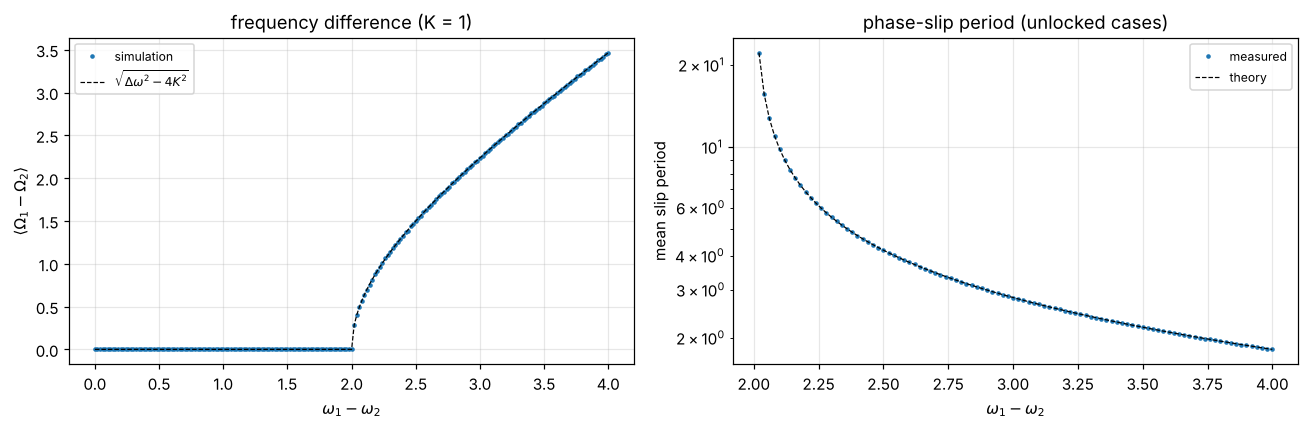

In [20]:
w1_grid = np.round(np.arange(2, 6 + 1e-12, 0.02), 3)
B = len(w1_grid); T_TR = 100.0
field = pair_field(w1_grid, 2.0, np.ones(B))
Y = np.tile([0.0, 1.0], (B, 1))
Y, _, _ = rk4_march(field, Y, T_TR, DT_OSC)
phi_tr = Y[:, 0] - Y[:, 1]
crossings = [[] for _ in range(B)]
t_now = T_TR; prev = phi_tr.copy()
while True:
    Y, ts_, rec = rk4_march(field, Y, t_now + 200, DT_OSC, probe=lambda Y: Y[:, 0] - Y[:, 1], t0=t_now)
    lvl = np.floor(rec / (2 * np.pi))
    for b in range(B):
        idx = np.flatnonzero(np.diff(lvl[:, b]) != 0)
        for i in idx:
            target = 2 * np.pi * max(lvl[i, b], lvl[i + 1, b])
            frac = (target - rec[i, b]) / (rec[i + 1, b] - rec[i, b])
            crossings[b].append(ts_[i] + frac * (ts_[i + 1] - ts_[i]))
    t_now += 200
    gap_now = np.abs(rec[-1] - phi_tr) / (t_now - T_TR)
    unlocked = gap_now > 1e-3
    if all(len(crossings[b]) >= 6 for b in np.flatnonzero(unlocked)) or t_now > 20000:
        break
T_END_D = t_now
mean_gap = (rec[-1] - phi_tr) / (T_END_D - T_TR)
slip_T = np.array([np.diff(c).mean() if len(c) >= 6 else np.nan for c in crossings])
dw = w1_grid - 2.0
locked = np.abs(mean_gap) < 1e-3
print(f"Integration extended to T = {T_END_D:.0f};  minimum # crossings among unlocked cases = "
      f"{min(len(crossings[b]) for b in np.flatnonzero(~locked))}")
print(f"Locked for Δω ∈ [{dw[locked].min():.2f}, {dw[locked].max():.2f}] → estimated locking range "
      f"{dw[locked].max():.2f} < Δω_c ≤ {dw[~locked].min():.2f}  (analytic 2K = 2)")

theory_T = 2 * np.pi / np.sqrt(np.where(dw > 2, dw**2 - 4, np.nan))
sel = ~locked
rel = np.nanmax(np.abs(slip_T[sel] - theory_T[sel]) / theory_T[sel])
print(f"Max relative deviation of measured slip period from 2π/√(Δω²−4K²): {rel:.2e}")
for v in (2.02, 2.1, 2.5, 3.0, 4.0):
    b = np.argmin(np.abs(dw - v))
    print(f"   Δω = {dw[b]:.2f}: <ΔΩ> = {mean_gap[b]:.5f}, T_slip(meas) = {slip_T[b]:.4f}, "
          f"T_slip(theory) = {theory_T[b]:.4f}, slips recorded = {len(crossings[b]) - 1}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(dw, mean_gap, ".", ms=4, label="simulation")
axes[0].plot(dw, np.sqrt(np.maximum(dw**2 - 4, 0)), "k--", lw=0.8, label=r"$\sqrt{\Delta\omega^2-4K^2}$")
axes[0].set_xlabel(r"$\omega_1-\omega_2$"); axes[0].set_ylabel(r"$\langle\Omega_1-\Omega_2\rangle$"); axes[0].legend()
axes[0].set_title("frequency difference (K = 1)")
axes[1].semilogy(dw[sel], slip_T[sel], ".", ms=4, label="measured")
axes[1].semilogy(dw[sel], theory_T[sel], "k--", lw=0.8, label="theory")
axes[1].set_xlabel(r"$\omega_1-\omega_2$"); axes[1].set_ylabel("mean slip period"); axes[1].legend()
axes[1].set_title("phase-slip period (unlocked cases)")
plt.tight_layout(); plt.show()

**Observations 3(d).** The locking range is $|\omega_1-\omega_2|\le2.00$, i.e. $|\Delta\omega|\le2K$, resolved to the grid spacing $0.02$. Outside it the mean frequency difference grows as $\sqrt{\Delta\omega^2-4K^2}$. The slip period measured from $2\pi$-crossings matches $2\pi/\sqrt{\Delta\omega^2-4K^2}$ to a relative error of $10^{-7}$. It diverges as $(\Delta\omega-2K)^{-1/2}$ at the edge of the locking range: $22.2$ at $\Delta\omega=2.02$, compared with $1.81$ at $\Delta\omega=4$. Even the slowest case recorded 8 complete slips by $T=300$, so no further extension was needed.

---
# Question 4 — Kuramoto model with all-to-all coupling

The coupling sum is evaluated in $O(N)$ through the order parameter:
$\frac{K}{N}\sum_j\sin(\theta_j-\theta_i)=K\,[\,\mathrm{Im}\,z\cos\theta_i-\mathrm{Re}\,z\sin\theta_i\,]$ with $z=re^{i\psi}=\frac1N\sum_je^{i\theta_j}$.
This identity is exact (not an approximation). It makes it practical to integrate an array of shape $(\text{realizations},\,n_K,\,N)$ in one RK4 call.

$N=200$; `default_rng(42)` draws first $\omega_i\sim\mathcal N(0,1)$ and then $\theta_i(0)\sim U[0,2\pi)$. Phases are unwrapped.

In [21]:
def kuramoto_field(omega, K):
    K = np.asarray(K, float)[..., None]

    def f(th):
        c, s = np.cos(th), np.sin(th)
        C = c.mean(-1, keepdims=True); S = s.mean(-1, keepdims=True)
        return omega + K * (S * c - C * s)
    return f


def order_param(th):
    z = np.exp(1j * th).mean(-1)
    return np.abs(z), np.angle(z)


N_OSC = 200
gen42 = np.random.default_rng(42)
omega = gen42.normal(0.0, 1.0, N_OSC)
theta0 = gen42.uniform(0.0, 2 * np.pi, N_OSC)
print(f"ω sample: mean {omega.mean():+.4f}, std {omega.std():.4f}, range [{omega.min():.3f}, {omega.max():.3f}]")
print(f"r(0) = {order_param(theta0)[0]:.4f};  K_c (infinite-N Gaussian) = 2/(π g(0)) = {2*np.sqrt(2*np.pi)/np.pi:.4f}")

ω sample: mean -0.0305, std 0.8797, range [-2.132, 2.914]
r(0) = 0.0202;  K_c (infinite-N Gaussian) = 2/(π g(0)) = 1.5958


## 4(a) $r(t)$ and phase snapshots for $K=0,1,1.5,2,4$
RK4, $\Delta t=0.01$.

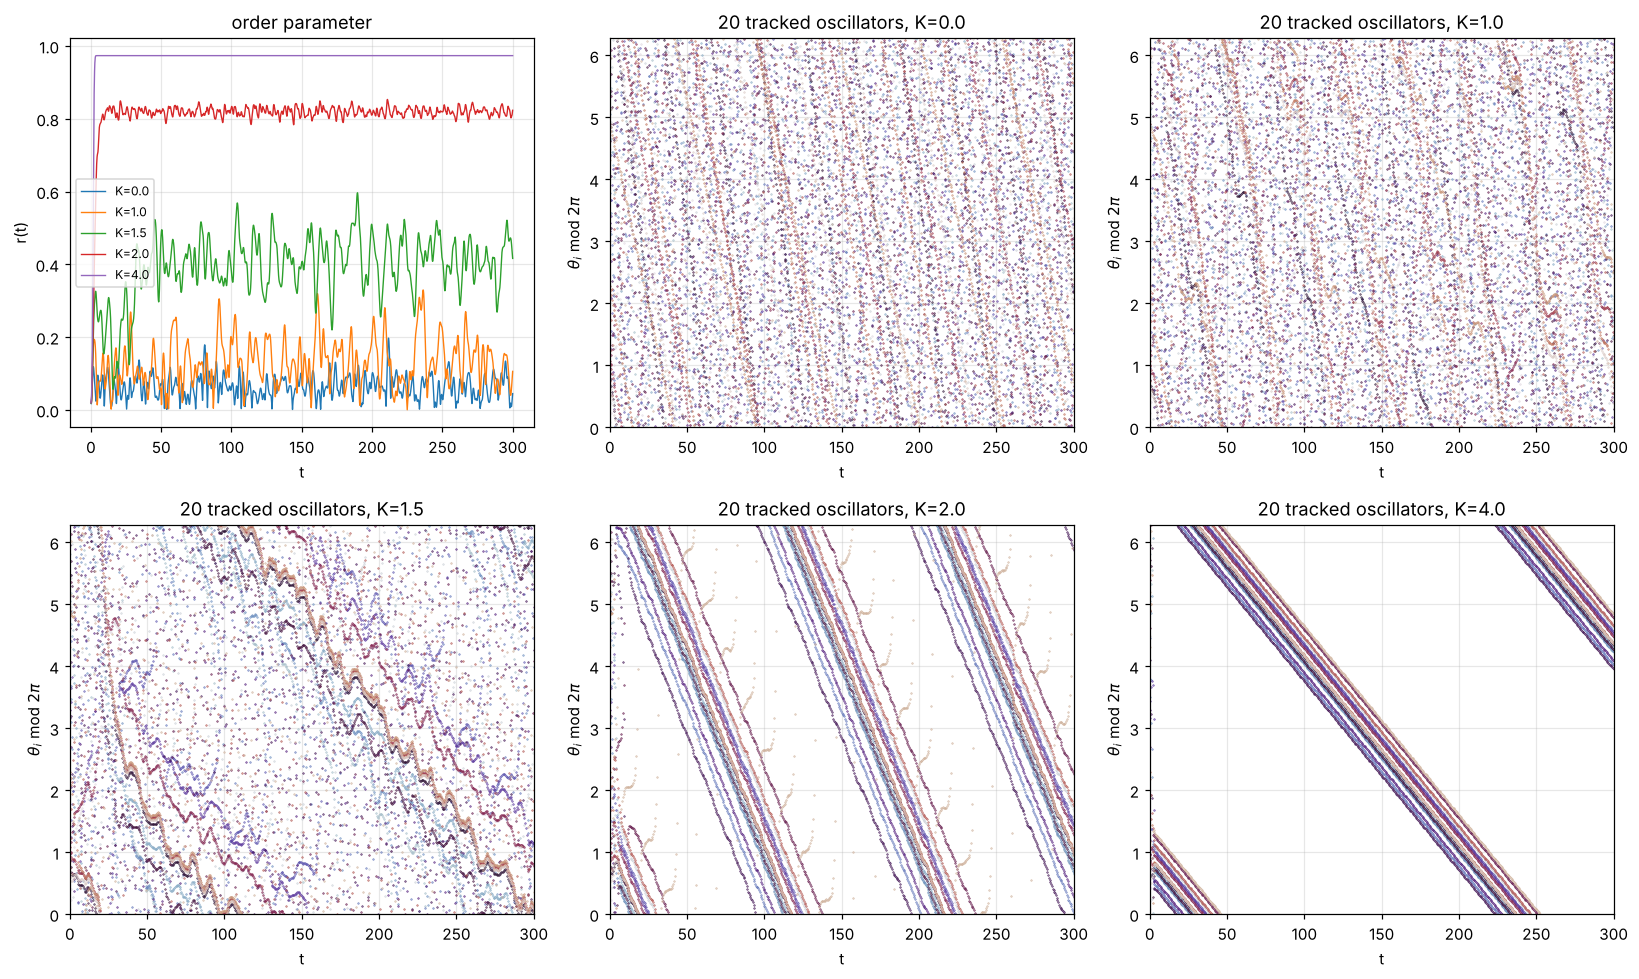

    K  <r>[200,300]      σ_r    min r    max r
  0.0        0.0651   0.0329   0.0021   0.1972
  1.0        0.1360   0.0692   0.0004   0.3295
  1.5        0.4111   0.0599   0.2553   0.5234
  2.0        0.8193   0.0109   0.7905   0.8530
  4.0        0.9733   0.0000   0.9733   0.9733


In [22]:
K4a = np.array([0, 1, 1.5, 2, 4.0])
watch = np.linspace(0, N_OSC - 1, 20).round().astype(int)
th_init = np.tile(theta0, (len(K4a), 1))
probe4 = lambda th: np.concatenate([order_param(th)[0][:, None], np.mod(th[:, watch], 2 * np.pi)], axis=1)
_, t4, rec4 = rk4_march(kuramoto_field(omega, K4a), th_init, 300, 0.01, probe=probe4, every=10)
r4 = rec4[:, :, 0]

fig = plt.figure(figsize=(15, 9))
ax0 = fig.add_subplot(2, 3, 1)
for j, K in enumerate(K4a):
    ax0.plot(t4, r4[:, j], lw=0.9, label=f"K={K}")
ax0.set_xlabel("t"); ax0.set_ylabel("r(t)"); ax0.set_title("order parameter"); ax0.legend()
for j, K in enumerate(K4a):
    ax = fig.add_subplot(2, 3, j + 2)
    sub = slice(None, None, 5)
    for q in range(20):
        ax.plot(t4[sub], rec4[sub, j, 1 + q], ".", ms=0.8, color=plt.cm.twilight(q / 20))
    ax.set_xlim(0, 300); ax.set_ylim(0, 2 * np.pi)
    ax.set_xlabel("t"); ax.set_ylabel(r"$\theta_i$ mod $2\pi$"); ax.set_title(f"20 tracked oscillators, K={K}")
plt.tight_layout(); plt.show()

print(f"{'K':>5s}{'<r>[200,300]':>14s}{'σ_r':>9s}{'min r':>9s}{'max r':>9s}")
for j, K in enumerate(K4a):
    m = t4 >= 200
    print(f"{K:5.1f}{window_mean(t4, r4[:, j], 200, 300):14.4f}{r4[m, j].std():9.4f}{r4[m, j].min():9.4f}{r4[m, j].max():9.4f}")

**Observations 4(a).**
* **K = 0 and 1:** incoherent. $r(t)$ fluctuates around a small value ($\bar r\approx0.07$ and $0.14$). The fluctuations have size $O(N^{-1/2})$ and are much larger at $K=1$. The phase plots show every oscillator drifting at its own speed.
* **K = 1.5:** just below $K_c^{\infty}\approx1.60$. Partial synchrony, with $\bar r\approx0.41$ and strong fluctuations. A visible cluster forms while many oscillators still drift through it.
* **K = 2:** a large locked cluster rotates together ($\bar r\approx0.82$). The remaining fast oscillators drift, so $r$ fluctuates slightly.
* **K = 4:** all oscillators lock. $r$ becomes constant ($0.973$) and the 20 traced phases move as parallel lines with the common slope $\Omega_c\approx-0.03$.

**Accuracy check.** For $K=2$ the run is repeated with $\Delta t=0.005$ and with DOP853 (`rtol=1e-10`). Pointwise phase errors can grow slowly over long times because the dynamics of a finite population is sensitive to small perturbations. For that reason both the short-time pointwise error and the time-averaged statistic used later are compared.

In [23]:
def kura_scipy(K):
    def f(t, th):
        z = np.exp(1j * th).mean()
        return omega + K * (z.imag * np.cos(th) - z.real * np.sin(th))
    return f


for K in (1.0, 2.0):
    j = list(K4a).index(K)
    _, tf, recf = rk4_march(kuramoto_field(omega, [K]), theta0[None], 300, 0.005, probe=lambda th: order_param(th)[0], every=20)
    ref = solve_ivp(kura_scipy(K), (0, 300), theta0, method="DOP853", rtol=1e-10, atol=1e-10, t_eval=t4)
    r_ref = np.abs(np.exp(1j * ref.y).mean(0))
    early = t4 <= 50
    print(f"K={K}: max|r(dt=.01)-r(dt=.005)| = {np.abs(r4[:, j] - recf[:, 0]).max():.2e};  "
          f"max|r-r_DOP853| (t≤50) = {np.abs(r4[early, j]-r_ref[early]).max():.2e}, (t≤300) = {np.abs(r4[:, j]-r_ref).max():.2e};  "
          f"<r> RK4 = {window_mean(t4, r4[:, j], 200, 300):.6f}, DOP853 = {window_mean(t4, r_ref, 200, 300):.6f}")

K=1.0: max|r(dt=.01)-r(dt=.005)| = 3.29e-10;  max|r-r_DOP853| (t≤50) = 2.75e-09, (t≤300) = 4.60e-08;  <r> RK4 = 0.136029, DOP853 = 0.136029


K=2.0: max|r(dt=.01)-r(dt=.005)| = 4.25e-09;  max|r-r_DOP853| (t≤50) = 6.16e-10, (t≤300) = 1.35e-08;  <r> RK4 = 0.819269, DOP853 = 0.819269


**Accuracy 4(a).** For $K=1$ and $K=2$ the RK4 run with $\Delta t=0.01$ agrees with $\Delta t=0.005$ to $\sim10^{-9}$ and with DOP853 to $\sim10^{-8}$ in $r(t)$, and $\bar r$ agrees to six decimals.

## 4(b) Sweep $K\in[0,4]$ (step 0.05): $\bar r$ and $\sigma_r$
RK4 with $\Delta t=0.02$ (step-size check against $\Delta t=0.01$ below). The order parameter is sampled every step; $\bar r$ and $\sigma_r$ use the trapezoid rule on $[200,300]$.

step-size check: max |r̄(dt=0.02) − r̄(dt=0.01)| over all K = 1.39e-02
steepest increase of r̄ between K = 1.45 and 1.50  (dr̄/dK = 2.76)
four steepest intervals: [1.30,1.35] (0.83), [1.45,1.50] (2.76), [1.50,1.55] (1.44), [1.60,1.65] (2.60)


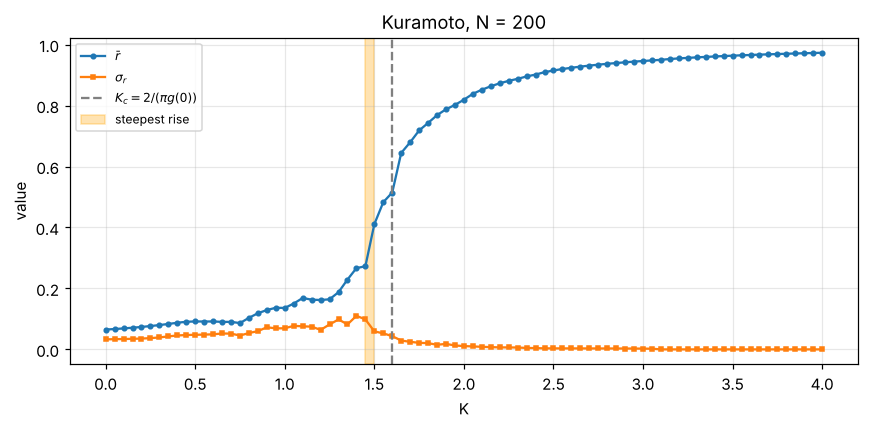

In [24]:
def kuramoto_stats(omega_arr, theta_arr, K_vals, t_end=300.0, win=100.0, dt=0.02, every=1):
    """omega_arr/theta_arr: (R, N) realizations; returns r̄, σ_r of shape (R, nK)."""
    om = omega_arr[:, None, :]
    th = np.broadcast_to(theta_arr[:, None, :], (omega_arr.shape[0], len(K_vals), omega_arr.shape[1])).copy()
    field = kuramoto_field(om, np.broadcast_to(K_vals, (omega_arr.shape[0], len(K_vals))))
    th, _, _ = rk4_march(field, th, t_end - win, dt)
    _, ts, rr = rk4_march(field, th, t_end, dt, probe=lambda x: order_param(x)[0], every=every, t0=t_end - win)
    a, b = t_end - win, t_end
    rbar = window_mean(ts, rr, a, b)
    sig = np.sqrt(window_mean(ts, (rr - rbar) ** 2, a, b))
    return rbar, sig


K_b4 = np.round(np.arange(0, 4 + 1e-12, 0.05), 3)
rb, sr = kuramoto_stats(omega[None], theta0[None], K_b4)
rb, sr = rb[0], sr[0]
rb_chk, _ = kuramoto_stats(omega[None], theta0[None], K_b4, dt=0.01)
print(f"step-size check: max |r̄(dt=0.02) − r̄(dt=0.01)| over all K = {np.abs(rb - rb_chk[0]).max():.2e}")
slope = np.diff(rb) / np.diff(K_b4)
i_s = np.argmax(slope)
print(f"steepest increase of r̄ between K = {K_b4[i_s]:.2f} and {K_b4[i_s+1]:.2f}  (dr̄/dK = {slope[i_s]:.2f})")
top = np.argsort(slope)[::-1][:4]
print("four steepest intervals:", ", ".join(f"[{K_b4[i]:.2f},{K_b4[i+1]:.2f}] ({slope[i]:.2f})" for i in sorted(top)))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(K_b4, rb, "o-", ms=3, label=r"$\bar r$")
ax.plot(K_b4, sr, "s-", ms=3, label=r"$\sigma_r$")
ax.axvline(2 * np.sqrt(2 * np.pi) / np.pi, color="gray", ls="--", label=r"$K_c=2/(\pi g(0))$")
ax.axvspan(K_b4[i_s], K_b4[i_s + 1], color="orange", alpha=0.3, label="steepest rise")
ax.set_xlabel("K"); ax.set_ylabel("value"); ax.set_title("Kuramoto, N = 200"); ax.legend()
plt.tight_layout(); plt.show()

**Observations 4(b).**
* $\bar r$ stays at the finite-size noise level ($\approx0.07$–$0.15$) up to $K\approx1.3$. It rises most steeply in $[1.45,1.50]$ (slope $2.8$), with a second steep step in $[1.60,1.65]$, and then approaches saturation ($\bar r\to0.97$).
* $\sigma_r$ is largest in the transition region ($K\approx1.1$–$1.5$), where small clusters keep forming and breaking. It becomes tiny once most oscillators are locked.
* The transition is close to the infinite-$N$ prediction $K_c=2/(\pi g(0))=1.60$. With $N=200$ it is shifted slightly lower and rounded.
* **Step-size remark (corrected from the method note above):** the largest difference between $\Delta t=0.02$ and $\Delta t=0.01$ is $1.4\times10^{-2}$. It occurs only in the transition region. There the finite-$N$ dynamics is irregular, so tiny differences decorrelate the trajectories, and a 100-unit average differs by an amount comparable to $\sigma_r$. This is statistical, not truncation error: away from the transition and in the accuracy check above, the differences are $\le10^{-8}$.

**Refinement and transient sensitivity.** Spacing $0.01$ over $[1.0,2.2]$, which brackets the steepest rise. Averages are taken over $[200,300]$ (original) and over $[900,1000]$, i.e. after a 9× longer transient.

transient 200: steepest (5-pt smoothed) rise near K ≈ 1.46–1.47
transient 900: steepest (5-pt smoothed) rise near K ≈ 1.43–1.44
max |r̄_long − r̄_short| = 0.0372 at K = 1.41;  mean |difference| = 0.0043


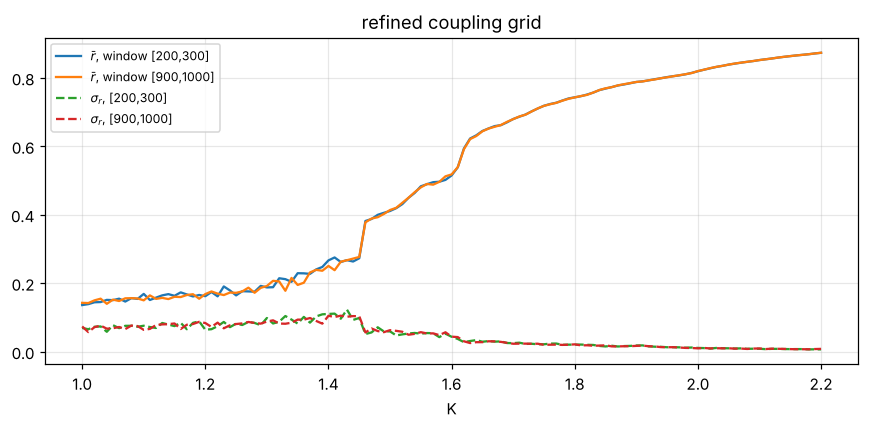

In [25]:
K_ref4 = np.round(np.arange(1.0, 2.2 + 1e-12, 0.01), 3)
rb_s, sr_s = kuramoto_stats(omega[None], theta0[None], K_ref4, t_end=300)
rb_l, sr_l = kuramoto_stats(omega[None], theta0[None], K_ref4, t_end=1000)
rb_s, sr_s, rb_l, sr_l = rb_s[0], sr_s[0], rb_l[0], sr_l[0]
for lab, rr in (("transient 200", rb_s), ("transient 900", rb_l)):
    sl = np.diff(rr) / 0.01; i = np.argmax(np.convolve(sl, np.ones(5) / 5, mode="same"))
    print(f"{lab}: steepest (5-pt smoothed) rise near K ≈ {K_ref4[i]:.2f}–{K_ref4[i+1]:.2f}")
print(f"max |r̄_long − r̄_short| = {np.abs(rb_l - rb_s).max():.4f} at K = {K_ref4[np.argmax(np.abs(rb_l - rb_s))]:.2f};"
      f"  mean |difference| = {np.abs(rb_l - rb_s).mean():.4f}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(K_ref4, rb_s, "-", label=r"$\bar r$, window [200,300]")
ax.plot(K_ref4, rb_l, "-", label=r"$\bar r$, window [900,1000]")
ax.plot(K_ref4, sr_s, "--", label=r"$\sigma_r$, [200,300]")
ax.plot(K_ref4, sr_l, "--", label=r"$\sigma_r$, [900,1000]")
ax.set_xlabel("K"); ax.set_title("refined coupling grid"); ax.legend()
plt.tight_layout(); plt.show()

**Observations 4(b) – refinement.** On the refined grid, the steepest smoothed rise is at $K\approx1.46$–$1.47$ with averaging over $[200,300]$ and at $K\approx1.43$–$1.44$ with the longer transient. The curves for the two windows lie on top of each other except in the transition region ($\max|\Delta\bar r|=0.037$ at $K=1.41$; mean difference $0.004$). The jumps of $\bar r$ near $K\approx1.46$ and $1.60$ are where groups of oscillators with similar $\omega_i$ join the cluster. For a fixed frequency sample these jumps are sharp, and the transition interval is robust to the transient length within about $\pm0.03$ in $K$.

## 4(c) Frequency entrainment for $K=1,2,4$
$\Omega_i=[\theta_i(300)-\theta_i(200)]/100$. The collective phase $\psi$ is sampled every step ($\Delta t=0.01$) on $[200,300]$ and unwrapped, which gives $\Omega_c$.

   K      r̄   min r       Ω_c   fraction |Ω_i−Ω_c|<0.01  max |Δψ| per step  #|ω_i|≤K r̄ (theory)
   1  0.1360  0.0004  -0.17502                     0.040             2.6248                 0.095
   2  0.8193  0.7904  -0.06344                     0.940             0.0015                 0.935
   4  0.9733  0.9733  -0.03045                     1.000             0.0003                 1.000


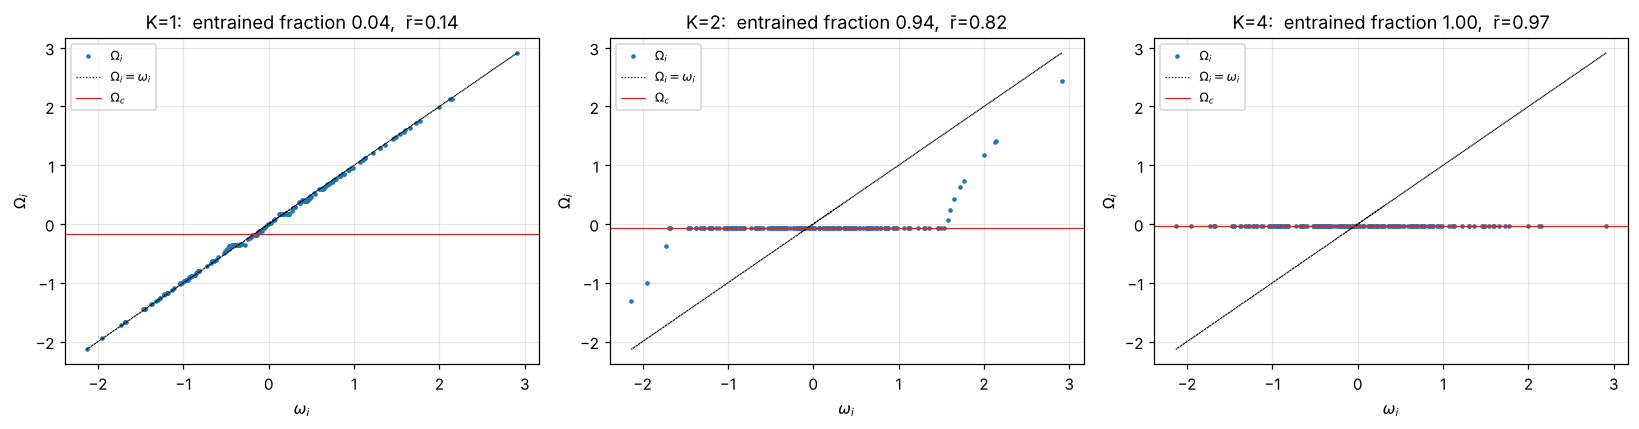

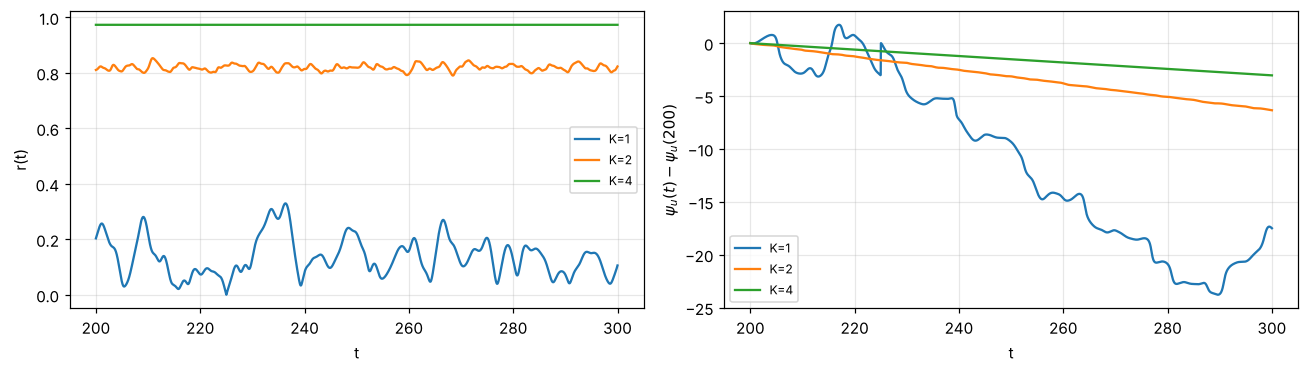

mean natural frequency of the sample: -0.03045 (expected locking frequency for large K)


In [26]:
K4c = np.array([1.0, 2.0, 4.0])
fld = kuramoto_field(omega, K4c)
th200, _, _ = rk4_march(fld, np.tile(theta0, (3, 1)), 200, 0.01)
th300, t_c, psi_rec = rk4_march(fld, th200, 300, 0.01, probe=lambda th: np.stack(order_param(th), -1), t0=200)
Omega = (th300 - th200) / 100
r_c, psi_c = psi_rec[:, :, 0], psi_rec[:, :, 1]
psi_u = np.unwrap(psi_c, axis=0)
Omega_c = (psi_u[-1] - psi_u[0]) / 100

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
print(f"{'K':>4s}{'r̄':>8s}{'min r':>8s}{'Ω_c':>10s}{'fraction |Ω_i−Ω_c|<0.01':>26s}{'max |Δψ| per step':>19s}{'#|ω_i|≤K r̄ (theory)':>22s}")
for j, K in enumerate(K4c):
    locked_frac = np.mean(np.abs(Omega[j] - Omega_c[j]) < 0.01)
    rbar = window_mean(t_c, r_c[:, j], 200, 300)
    jump = np.abs(np.diff(psi_u[:, j])).max()
    theo = np.mean(np.abs(omega - omega.mean()) <= K * rbar)
    print(f"{K:4.0f}{rbar:8.4f}{r_c[:, j].min():8.4f}{Omega_c[j]:10.5f}{locked_frac:26.3f}{jump:19.4f}{theo:22.3f}")
    ax = axes[j]
    ax.plot(omega, Omega[j], ".", ms=4, label=r"$\Omega_i$")
    ax.plot(omega, omega, "k:", lw=0.8, label=r"$\Omega_i=\omega_i$")
    ax.axhline(Omega_c[j], color="tab:red", lw=0.8, label=r"$\Omega_c$")
    ax.set_xlabel(r"$\omega_i$"); ax.set_ylabel(r"$\Omega_i$")
    ax.set_title(f"K={K:.0f}:  entrained fraction {locked_frac:.2f},  r̄={rbar:.2f}"); ax.legend()
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for j, K in enumerate(K4c):
    axes[0].plot(t_c, r_c[:, j], label=f"K={K:.0f}")
    axes[1].plot(t_c, psi_u[:, j] - psi_u[0, j], label=f"K={K:.0f}")
axes[0].set_ylabel("r(t)"); axes[1].set_ylabel(r"$\psi_u(t)-\psi_u(200)$")
for ax in axes:
    ax.set_xlabel("t"); ax.legend()
plt.tight_layout(); plt.show()
print(f"mean natural frequency of the sample: {omega.mean():+.5f} (expected locking frequency for large K)")

**Observations 4(c).**
* **K = 1:** $r$ is small and drops to $4\times10^{-4}$. When $r\approx0$ the angle $\psi$ of $re^{i\psi}$ is essentially undefined, and it jumps by up to $2.6$ rad in a single step of $0.01$. The unwrapped $\psi_u$ therefore wanders erratically, so $\Omega_c=-0.175$ is not meaningful. Only 4% of oscillators fall within $0.01$ of it, by coincidence. The $\Omega_i$ lie on the line $\Omega_i=\omega_i$ (no entrainment).
* **K = 2:** 94% of oscillators are entrained (the plateau in $\Omega_i$ vs $\omega_i$). This is very close to the fraction with $|\omega_i-\bar\omega|\le K\bar r$ (93.5%) predicted by the locking condition. The fastest oscillators drift, with $\Omega_i$ approaching $\omega_i$.
* **K = 4:** 100% are entrained, and $\Omega_c=-0.03045$ equals the sample mean $\bar\omega$ exactly. Summing the equations shows that $\sum_i\dot\theta_i=\sum_i\omega_i$, so a fully locked population must rotate at $\bar\omega$.
* Across the three cases, frequency entrainment tracks $r$: no entrainment at $\bar r=0.14$, 94% at $0.82$, and full entrainment at $0.97$. $\psi$ is only reliable when $r$ stays well away from zero.

## 4(d) Finite-size effects: $N=50,100,400$, 10 realizations each
Each realization has its own `SeedSequence([N, realization])` generator, so the frequency and phase samples are fresh, reproducible, and fixed across that realization's whole $K$-sweep. All $10\times81$ systems of one size are integrated as a single $(10,81,N)$ RK4 batch with $\Delta t=0.05$; $r$ is sampled every $0.1$. The step-size check below compares $\Delta t=0.05$ against $0.02$ for one realization.

N=  50: done in  48.7s;  step check max|r̄(0.05)−r̄(0.02)| = 2.45e-02


N= 100: done in 100.5s;  step check max|r̄(0.05)−r̄(0.02)| = 2.07e-02


N= 400: done in 405.4s;  step check max|r̄(0.05)−r̄(0.02)| = 1.16e-02


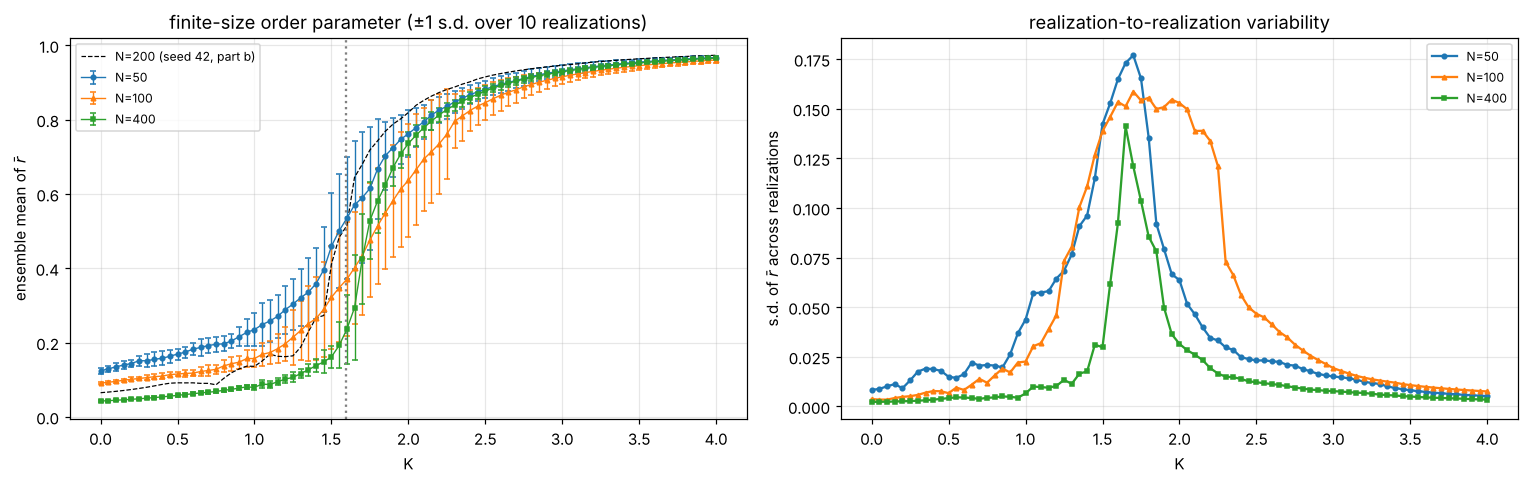

    N  <r̄>(K=0)  √π/(2√N)  mean s.d.(K≤1)  s.d. max  at K K(<r̄>=0.3) K(<r̄>=0.7)
   50     0.1240    0.1253          0.0186    0.1769  1.70       1.238       1.846
  100     0.0911    0.0886          0.0100    0.1587  1.70       1.467       2.115
  400     0.0426    0.0443          0.0037    0.1411  1.65       1.652       1.940

Total notebook run time: 24.5 min


In [27]:
sizes = (50, 100, 400)
ens = {}
for n in sizes:
    oms, ths = [], []
    for rlz in range(10):
        gsz = np.random.default_rng([n, rlz])
        oms.append(gsz.normal(0, 1, n)); ths.append(gsz.uniform(0, 2 * np.pi, n))
    oms, ths = np.array(oms), np.array(ths)
    t_s = time.time()
    rbar_e, _ = kuramoto_stats(oms, ths, K_b4, dt=0.05, every=2)
    ens[n] = rbar_e
    chk, _ = kuramoto_stats(oms[:1], ths[:1], K_b4, dt=0.02, every=5)
    print(f"N={n:4d}: done in {time.time()-t_s:5.1f}s;  step check max|r̄(0.05)−r̄(0.02)| = {np.abs(chk[0]-rbar_e[0]).max():.2e}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for n, mk in zip(sizes, "o^s"):
    m, s = ens[n].mean(0), ens[n].std(0)
    axes[0].errorbar(K_b4, m, yerr=s, fmt=mk + "-", ms=3, capsize=2, lw=0.9, label=f"N={n}")
    axes[1].plot(K_b4, s, mk + "-", ms=3, label=f"N={n}")
axes[0].plot(K_b4, rb, "k--", lw=0.8, label="N=200 (seed 42, part b)")
axes[0].axvline(2 * np.sqrt(2 * np.pi) / np.pi, color="gray", ls=":")
axes[0].set_xlabel("K"); axes[0].set_ylabel(r"ensemble mean of $\bar r$"); axes[0].legend()
axes[0].set_title("finite-size order parameter (±1 s.d. over 10 realizations)")
axes[1].set_xlabel("K"); axes[1].set_ylabel(r"s.d. of $\bar r$ across realizations"); axes[1].legend()
axes[1].set_title("realization-to-realization variability")
plt.tight_layout(); plt.show()

print(f"{'N':>5s}{'<r̄>(K=0)':>11s}{'√π/(2√N)':>10s}{'mean s.d.(K≤1)':>16s}{'s.d. max':>10s}{'at K':>6s}{'K(<r̄>=0.3)':>12s}{'K(<r̄>=0.7)':>12s}")
for n in sizes:
    m, s = ens[n].mean(0), ens[n].std(0)
    k03 = np.interp(0.3, np.maximum.accumulate(m), K_b4); k07 = np.interp(0.7, np.maximum.accumulate(m), K_b4)
    print(f"{n:5d}{m[0]:11.4f}{np.sqrt(np.pi)/(2*np.sqrt(n)):10.4f}{s[K_b4 <= 1].mean():16.4f}{s.max():10.4f}"
          f"{K_b4[np.argmax(s)]:6.2f}{k03:12.3f}{k07:12.3f}")
print(f"\nTotal notebook run time: {(time.time()-CLOCK)/60:.1f} min")

**Observations 4(d).**
* **Residual order at $K=0$:** $\langle\bar r\rangle=0.124,\,0.091,\,0.043$ for $N=50,100,400$. This matches the random-phase estimate $\sqrt{\pi}/(2\sqrt N)=0.125,\,0.089,\,0.044$, so the incoherent "order" is pure finite-size noise that disappears as $N^{-1/2}$.
* **Variability:** the spread between realizations is small in the incoherent regime and shrinks with $N$ (mean s.d. for $K\le1$: $0.019\to0.010\to0.004$). It is largest in the transition region ($K\approx1.65$–$1.7$), where each sample's particular frequencies decide when clusters form. The peak s.d. also decreases with $N$ ($0.18\to0.16\to0.14$).
* **Transition interval:** with $N=400$ the rise is the sharpest ($\langle\bar r\rangle$ goes from $0.3$ to $0.7$ between $K=1.65$ and $1.94$) and lies closest to $K_c^{\infty}=1.60$. For small $N$ the curves are smeared out and appear to start earlier ($K(\bar r=0.3)=1.24$ for $N=50$), partly because the noise floor is already high. As $N$ grows the curves approach the sharp infinite-$N$ transition.
* For a single realization, the step-size check ($\Delta t=0.05$ vs $0.02$) differs by at most $2.5\times10^{-2}$, again only inside the transition region, for the same reason as in 4(b). This is well below the realization-to-realization spread there ($\approx0.15$).

---
## Summary
* **SIS:** the mean-field epidemic threshold is $\lambda_c=\mu/\Lambda_{max}$ ($0.0768$ ER, $0.0501$ BA), confirmed to within $5\times10^{-4}$ once the integration time is long enough. Heterogeneity (BA) lowers the threshold. Node infection depends on degree *and* on how central the neighbours are. Hub protection beats random protection because it lowers $\Lambda_{max}$.
* **SIR:** the threshold is the same, and conservation holds to $10^{-14}$. Hub seeding speeds up and raises the peak but leaves the final size almost unchanged. Hub immunization reduces the outbreak far more than random immunization, especially on BA (85–89% vs 21–27%).
* **Two oscillators:** they lock exactly when $K\ge|\Delta\omega|/2$. The locked phase $\arcsin(\Delta\omega/2K)$ does not depend on initial conditions, and the slip period $2\pi/\sqrt{\Delta\omega^2-4K^2}$ is reproduced to $10^{-7}$.
* **Kuramoto:** for $N=200$ the onset of synchrony is close to $K_c=2/(\pi g(0))\approx1.6$. The residual order scales as $N^{-1/2}$, and the transition sharpens as $N$ grows. Frequency entrainment follows the order parameter.
